# Tumor Segmentation in MRI Volumes

### Loading Data

In [1]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("/l/users/faiz.ramadhan/brain_tumor/Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
split_df = pd.read_csv(SPLIT_FILE)

assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}

for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


## Inspect Data

In [2]:
from pathlib import Path
import nibabel as nib
import numpy as np

images_dir = DATA_ROOT / "imagesTr"
labels_dir = DATA_ROOT / "labelsTr"

# Get image cases
image_files = sorted(
    p for p in images_dir.glob("*.nii.gz")
    if not p.name.startswith("._")
)

# Load at least 3 cases
for image_path in image_files[:3]:
    case_id = image_path.name.replace(".nii.gz", "")
    label_path = labels_dir / f"{case_id}.nii.gz"

    image_nii = nib.load(image_path)
    label_nii = nib.load(label_path)

    image = image_nii.get_fdata()
    label = label_nii.get_fdata()

    print("=" * 80)
    print(f"CASE: {case_id}")
    print(f"Image shape: {image.shape}")
    print(f"Label shape: {label.shape}")

    print("\nAffine:")
    print(image_nii.affine)

    print("\nOrientation:")
    print(nib.aff2axcodes(image_nii.affine))

    print("\nVoxel spacing:")
    print(image_nii.header.get_zooms()[:3])

    print("\nLabel values:")
    print(np.unique(label))

CASE: BRATS_001
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]
CASE: BRATS_002
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]
CASE: BRATS_003
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]


Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Selected voxel: (np.int64(157), np.int64(116), np.int64(67))
Selected slice: 67
4


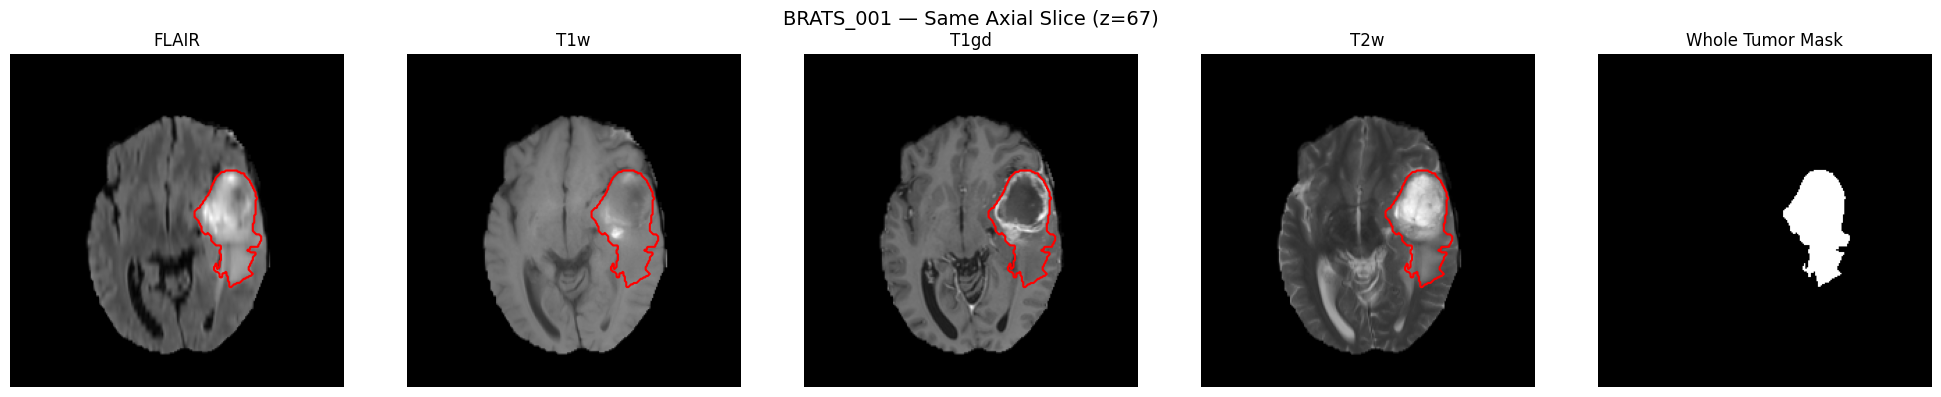

In [3]:
import matplotlib.pyplot as plt

case = "BRATS_001"

image_path = DATA_ROOT / "imagesTr" / f"{case}.nii.gz"
label_path = DATA_ROOT / "labelsTr" / f"{case}.nii.gz"

image_nii = nib.load(image_path)
label_nii = nib.load(label_path)

image = image_nii.get_fdata()
label = label_nii.get_fdata()

print("Image shape:", image.shape)
print("Label shape:", label.shape)


# Channel order from dataset.json
modalities = {
    "FLAIR": image[..., 0],
    "T1w":   image[..., 1],
    "T1gd":  image[..., 2],
    "T2w":   image[..., 3],
}


# Tumor mask
# 0 = background
# 1 = edema
# 2 = non-enhancing tumor
# 3 = enhancing tumor
#
# Whole tumor = labels 1 + 2 + 3

whole_tumor = (label > 0).astype(np.uint8)


# Find a slice containing tumor

tumor_voxels = np.argwhere(whole_tumor > 0)

# Use the spatial centroid of all tumor voxels
x, y, z = np.rint(tumor_voxels.mean(axis=0)).astype(int)

print("Selected voxel:", (x, y, z))
print("Selected slice:", z)


# --------------------------------------------------
# Display
# --------------------------------------------------

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

print(len(modalities.values()))

for ax, (title, modality_image) in zip(axes[:4], modalities.items()):

    ax.imshow(
        modality_image[:, :, z].T,
        cmap="gray",
        origin="lower"
    )

    ax.contour(
        whole_tumor[:, :, z].T,
        levels=[0.5],
        linewidths=1.5,
        colors='red'
    )

    ax.set_title(title)
    ax.axis("off")

# Whole-tumor reference mask
axes[4].imshow(
    whole_tumor[:, :, z].T,
    cmap="gray",
    origin="lower"
)

axes[4].set_title("Whole Tumor Mask")
axes[4].axis("off")


plt.suptitle(
    f"{case} — Same Axial Slice (z={z})",
    fontsize=14
)

plt.tight_layout()
plt.show()

Selected voxel: (np.int64(157), np.int64(116), np.int64(67))


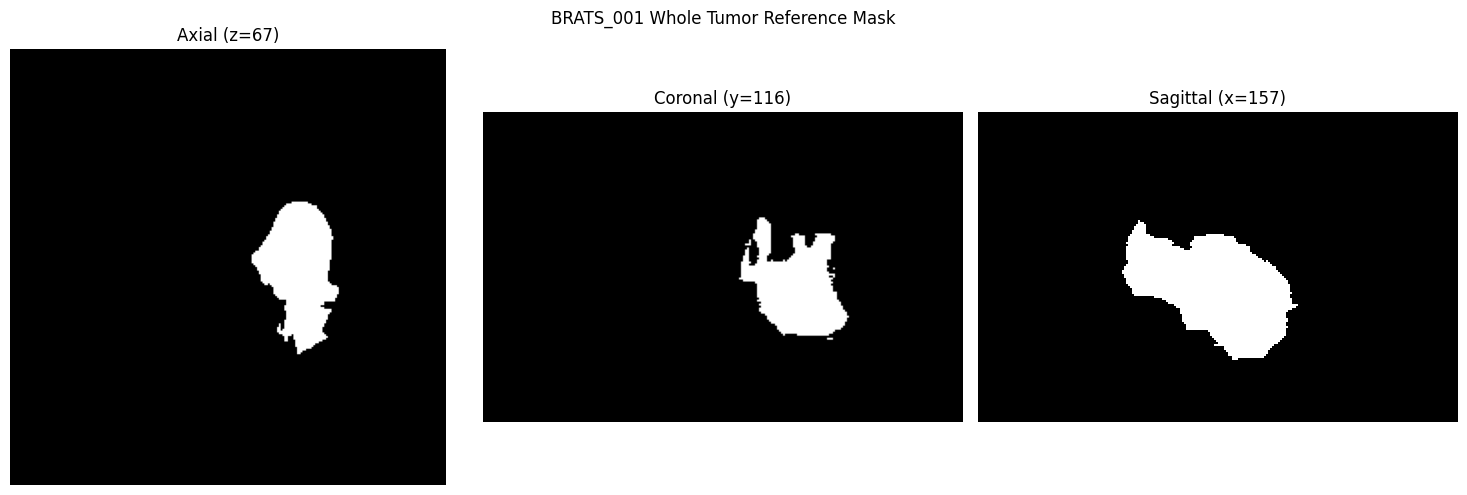

In [4]:
# Find the spatial centroid of the tumor
tumor_voxels = np.argwhere(whole_tumor)
x, y, z = np.rint(tumor_voxels.mean(axis=0)).astype(int)

print("Selected voxel:", (x, y, z))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Axial: XY plane
axes[0].imshow(
    whole_tumor[:, :, z].T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title(f"Axial (z={z})")

# Coronal: XZ plane
axes[1].imshow(
    whole_tumor[:, y, :].T,
    cmap="gray",
    origin="lower"
)
axes[1].set_title(f"Coronal (y={y})")

# Sagittal: YZ plane
axes[2].imshow(
    whole_tumor[x, :, :].T,
    cmap="gray",
    origin="lower"
)
axes[2].set_title(f"Sagittal (x={x})")

for ax in axes:
    ax.axis("off")

plt.suptitle("BRATS_001 Whole Tumor Reference Mask")
plt.tight_layout()
plt.show()

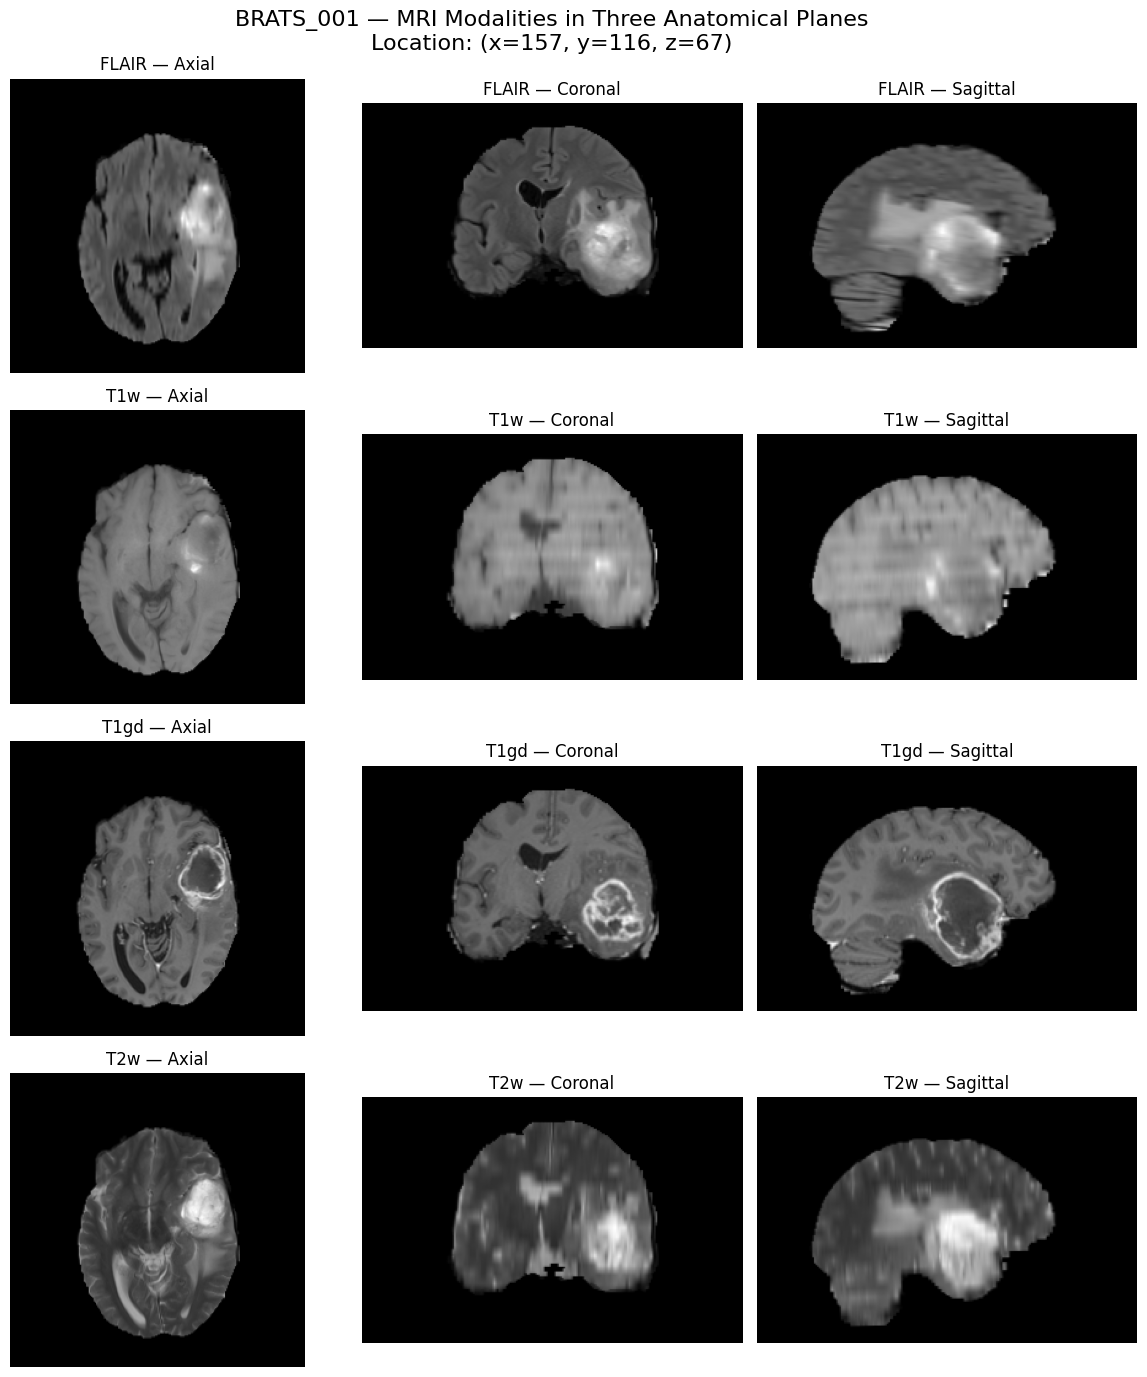

In [5]:
# --------------------------------------------------
# Plot: 4 rows × 3 columns
# --------------------------------------------------

fig, axes = plt.subplots(
    4, 3,
    figsize=(12, 14)
)

for row, (name, volume) in enumerate(modalities.items()):

    # Axial
    axes[row, 0].imshow(
        volume[:, :, z].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 0].set_title(f"{name} — Axial")

    # Coronal
    axes[row, 1].imshow(
        volume[:, y, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 1].set_title(f"{name} — Coronal")

    # Sagittal
    axes[row, 2].imshow(
        volume[x, :, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 2].set_title(f"{name} — Sagittal")

    for col in range(3):
        axes[row, col].axis("off")


plt.suptitle(
    f"BRATS_001 — MRI Modalities in Three Anatomical Planes\n"
    f"Location: (x={x}, y={y}, z={z})",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Data Split

In [6]:
split_df = pd.read_csv("assignment2_split.csv")
display(split_df)

display(split_df['split'].value_counts())

,case_id,split,image_relpath,label_relpath
0,BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz
1,BRATS_002,test,imagesTr/BRATS_002.nii.gz,labelsTr/BRATS_002.nii.gz
2,BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz
3,BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz
4,BRATS_005,train,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz
...,...,...,...,...
479,BRATS_480,train,imagesTr/BRATS_480.nii.gz,labelsTr/BRATS_480.nii.gz
480,BRATS_481,test,imagesTr/BRATS_481.nii.gz,labelsTr/BRATS_481.nii.gz
481,BRATS_482,test,imagesTr/BRATS_482.nii.gz,labelsTr/BRATS_482.nii.gz
482,BRATS_483,train,imagesTr/BRATS_483.nii.gz,labelsTr/BRATS_483.nii.gz


split
train         338
test           73
validation     73
Name: count, dtype: int64

In [7]:
def calculate_tumor_volume(label_relpath):
    """Calculate whole-tumor volume in mm³ from a reference mask."""

    label_path = DATA_ROOT / label_relpath

    label_nii = nib.load(label_path)
    label = label_nii.get_fdata()

    # Whole tumor = edema + non-enhancing tumor + enhancing tumor
    whole_tumor = label > 0

    # Voxel spacing in mm
    spacing = label_nii.header.get_zooms()[:3]

    # Volume of one voxel
    voxel_volume = np.prod(spacing)

    # Number of tumor voxels × volume per voxel
    tumor_volume_mm3 = np.sum(whole_tumor) * voxel_volume

    return tumor_volume_mm3

In [8]:
split_df['tumor_volume'] = split_df['label_relpath'].apply(lambda x: calculate_tumor_volume(x))
split_df.head()

,case_id,split,image_relpath,label_relpath,tumor_volume
0,BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz,111724.0
1,BRATS_002,test,imagesTr/BRATS_002.nii.gz,labelsTr/BRATS_002.nii.gz,63061.0
2,BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz,173927.0
3,BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz,120660.0
4,BRATS_005,train,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz,80680.0


In [9]:
train_df = split_df[split_df['split']=='train'].drop('split', axis=1).reset_index(drop=True)
val_df = split_df[split_df['split']=='validation'].drop('split', axis=1).reset_index(drop=True)
test_df = split_df[split_df['split']=='test'].drop('split', axis=1).reset_index(drop=True)

train_ids = set(train_df['case_id'])
val_ids = set(val_df['case_id'])
test_ids = set(test_df['case_id'])
assert train_ids.isdisjoint(val_ids), 'train/validation leakage'
assert train_ids.isdisjoint(test_ids), 'train/test leakage'
assert val_ids.isdisjoint(test_ids), 'validation/test leakage'

print("No intersection in train, val, and test")

print(f"train: {len(train_df)}")
print(f"val: {len(val_df)}")
print(f"test: {len(test_df)}")
train_df.head()

No intersection in train, val, and test
train: 338
val: 73
test: 73


,case_id,image_relpath,label_relpath,tumor_volume
0,BRATS_001,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz,111724.0
1,BRATS_003,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz,173927.0
2,BRATS_004,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz,120660.0
3,BRATS_005,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz,80680.0
4,BRATS_007,imagesTr/BRATS_007.nii.gz,labelsTr/BRATS_007.nii.gz,61085.0


Train


count       338.000000
mean     102964.050296
std       56960.257869
min        8478.000000
25%       60023.000000
50%       95484.500000
75%      143920.750000
max      265254.000000
Name: tumor_volume, dtype: float64

Val


count        73.000000
mean     100764.835616
std       62950.123009
min        7285.000000
25%       51853.000000
50%       91560.000000
75%      148062.000000
max      266936.000000
Name: tumor_volume, dtype: float64

Test


count        73.000000
mean     107388.123288
std       66278.031654
min       10101.000000
25%       54356.000000
50%       89113.000000
75%      157749.000000
max      318345.000000
Name: tumor_volume, dtype: float64

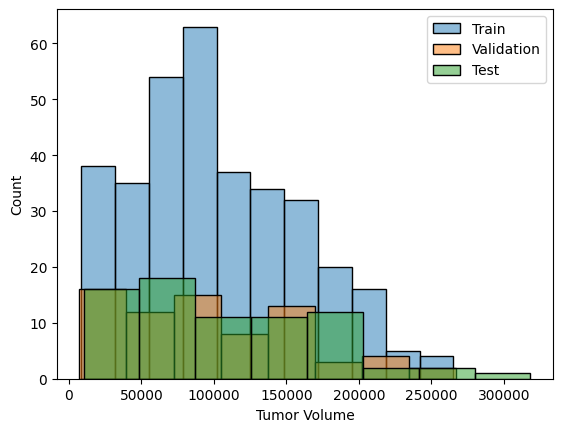

In [10]:
import seaborn as sns

print("Train")
display(train_df['tumor_volume'].describe())

print("Val")
display(val_df['tumor_volume'].describe())

print("Test")
display(test_df['tumor_volume'].describe())

sns.histplot(train_df['tumor_volume'], label='Train', alpha=0.5)
sns.histplot(val_df['tumor_volume'], label='Validation', alpha=0.5)
sns.histplot(test_df['tumor_volume'], label='Test', alpha=0.5)

plt.legend()
plt.xlabel('Tumor Volume')
plt.ylabel('Count')
plt.show()

<Axes: xlabel='tumor_volume', ylabel='Density'>

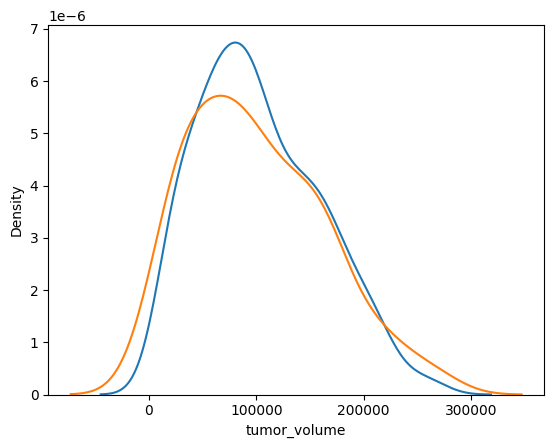

In [11]:
sns.kdeplot(train_df['tumor_volume'])
sns.kdeplot(val_df['tumor_volume'])

## Preprocess and Dataloader

In [12]:
def normalize_image(image):
    """Normalize each MRI channel using its non-zero brain voxels."""
    image = image.clone()
    for c in range(image.shape[0]):
        brain = image[c] != 0  # exclude zero-padded background
        if brain.any():
            mean = image[c][brain].mean()
            std = image[c][brain].std(unbiased=False)
            image[c][brain] = (image[c][brain] - mean) / std.clamp_min(1e-8)
    return image

def augment(image, label, probability=0.5):
    """Apply a paired random left-right flip to a training patch."""
    # [C, D, H, W]: H corresponds to the original NIfTI left-right axis.
    # Avoid superior-inferior flips, which would be anatomically implausible.
    if torch.rand(()) < probability:
        image = torch.flip(image, dims=[2])
        label = torch.flip(label, dims=[2])
    return image, label

In [13]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


class BraTSPatchDataset(Dataset):
    """
    BraTS patch dataset.

    Train:
        Uniformly samples one random patch per case.

    Validation/Test:
        Extracts all patches using a sliding window.

    Image:
        [C, D, H, W]

    Mask:
        [1, D, H, W]
    """

    def __init__(
        self,
        df,
        root_dir,
        patch_size=(96, 96, 96),
        stride=(48, 48, 48),
        train=False,
    ):
        self.df = df.reset_index(drop=True)
        self.root_dir = Path(root_dir)

        self.patch_size = patch_size
        self.stride = stride
        self.train = train

        if train:
            # One randomly sampled patch per dataset item
            self.samples = None
        else:
            # Precompute all sliding-window locations
            self.samples = self._make_sliding_window_index()

    # --------------------------------------------------
    # Basic
    # --------------------------------------------------

    def __len__(self):
        if self.train:
            return len(self.df)

        return len(self.samples)

    # --------------------------------------------------
    # Load one case
    # --------------------------------------------------

    def _load_case(self, case_idx):

        row = self.df.iloc[case_idx]

        image_path = self.root_dir / row["image_relpath"]
        label_path = self.root_dir / row["label_relpath"]

        image = nib.load(image_path).get_fdata()
        label = nib.load(label_path).get_fdata()

        # NIfTI image:
        # [H, W, D, C]
        #
        # Convert to:
        # [C, D, H, W]
        image = np.transpose(image, (3, 2, 0, 1))

        # Label:
        # [H, W, D] -> [D, H, W]
        label = np.transpose(label, (2, 0, 1))

        # Binary segmentation mask
        label = (label > 0).astype(np.float32)

        # Convert to tensors
        image = torch.from_numpy(image.copy()).float()

        label = torch.from_numpy(label.copy()).float()
        label = label.unsqueeze(0)

        # Normalize the full volume before extracting patches.
        image = normalize_image(image)

        # Pad image and mask identically if any dimension is smaller
        # than the requested patch. Existing BraTS volumes need no pad,
        # but this guarantees a fixed output shape for every valid input.
        image, label = self._pad_to_patch_size(image, label)

        return image, label

    # --------------------------------------------------
    # Consistent spatial padding
    # --------------------------------------------------

    def _pad_to_patch_size(self, image, label):
        """Symmetrically zero-pad image and label to at least patch_size."""
        _, D, H, W = image.shape
        pd, ph, pw = self.patch_size

        add_d = max(pd - D, 0)
        add_h = max(ph - H, 0)
        add_w = max(pw - W, 0)

        # F.pad order is (W left/right, H left/right, D left/right).
        padding = (
            add_w // 2, add_w - add_w // 2,
            add_h // 2, add_h - add_h // 2,
            add_d // 2, add_d - add_d // 2,
        )

        if any(padding):
            image = F.pad(image, padding, mode="constant", value=0)
            label = F.pad(label, padding, mode="constant", value=0)

        return image, label

    # --------------------------------------------------
    # Valid patch starts
    # --------------------------------------------------

    def _get_starts(self, size, patch, stride):

        if size <= patch:
            return [0]

        starts = list(range(0, size - patch + 1, stride))

        # Make sure the final part of the volume is covered
        final_start = size - patch

        if starts[-1] != final_start:
            starts.append(final_start)

        return starts

    # --------------------------------------------------
    # Create sliding-window index
    # --------------------------------------------------

    def _make_sliding_window_index(self):

        samples = []

        for case_idx in range(len(self.df)):

            # Load only to determine spatial dimensions
            row = self.df.iloc[case_idx]

            image_path = self.root_dir / row["image_relpath"]

            image = nib.load(image_path)

            # Original shape:
            # [H, W, D, C]
            H, W, D, C = image.shape

            pd, ph, pw = self.patch_size
            sd, sh, sw = self.stride

            d_starts = self._get_starts(D, pd, sd)
            h_starts = self._get_starts(H, ph, sh)
            w_starts = self._get_starts(W, pw, sw)

            for d in d_starts:
                for h in h_starts:
                    for w in w_starts:

                        samples.append(
                            (
                                case_idx,
                                d,
                                h,
                                w,
                            )
                        )

        return samples

    # --------------------------------------------------
    # Extract patch
    # --------------------------------------------------

    def _extract_patch(
        self,
        image,
        label,
        d,
        h,
        w,
    ):

        pd, ph, pw = self.patch_size

        # Identical coordinates keep every MRI channel aligned with its mask.
        image_patch = image[
            :,
            d:d + pd,
            h:h + ph,
            w:w + pw,
        ]

        label_patch = label[
            :,
            d:d + pd,
            h:h + ph,
            w:w + pw,
        ]

        return image_patch, label_patch

    # --------------------------------------------------
    # Uniform random patch
    # --------------------------------------------------

    def _random_patch(self, image, label):

        _, D, H, W = image.shape

        pd, ph, pw = self.patch_size

        # Uniformly sample valid starting coordinates
        d = np.random.randint(0, D - pd + 1)
        h = np.random.randint(0, H - ph + 1)
        w = np.random.randint(0, W - pw + 1)

        return self._extract_patch(
            image,
            label,
            d,
            h,
            w,
        ), (d, h, w)

    # --------------------------------------------------
    # Get item
    # --------------------------------------------------

    def __getitem__(self, idx):

        if self.train:

            # Dataset index corresponds to a case
            case_idx = idx

            image, label = self._load_case(case_idx)

            (image_patch, label_patch), location = self._random_patch(
                image,
                label,
            )

            # Augmentation is training-only and keeps image/mask aligned.
            image_patch, label_patch = augment(image_patch, label_patch)

        else:

            # Sliding-window evaluation
            case_idx, d, h, w = self.samples[idx]

            image, label = self._load_case(case_idx)

            image_patch, label_patch = self._extract_patch(
                image,
                label,
                d,
                h,
                w,
            )

            location = (d, h, w)

        return {
            "image": image_patch,
            "mask": label_patch,
            "case_idx": case_idx,
            "location": location,
        }

In [14]:
PATCH_SIZE = (96, 96, 96)
STRIDE = (48, 48, 48)

train_dataset = BraTSPatchDataset(
    train_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    train=True,
)

val_dataset = BraTSPatchDataset(
    val_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    train=False,
)

test_dataset = BraTSPatchDataset(
    test_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    train=False,
)

In [15]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
)

Raw shape: torch.Size([240, 240, 155, 4])
Raw min/max: 0.0 2346.0
Processed shape: torch.Size([4, 155, 240, 240])
Processed min/max: -4.142197132110596 8.075838088989258

Post-normalization statistics (non-zero brain voxels):
FLAIR: mean= 0.0000, std=1.0000
T1w  : mean=-0.0000, std=1.0000
T1gd : mean=-0.0000, std=1.0000
T2w  : mean= 0.0000, std=1.0000


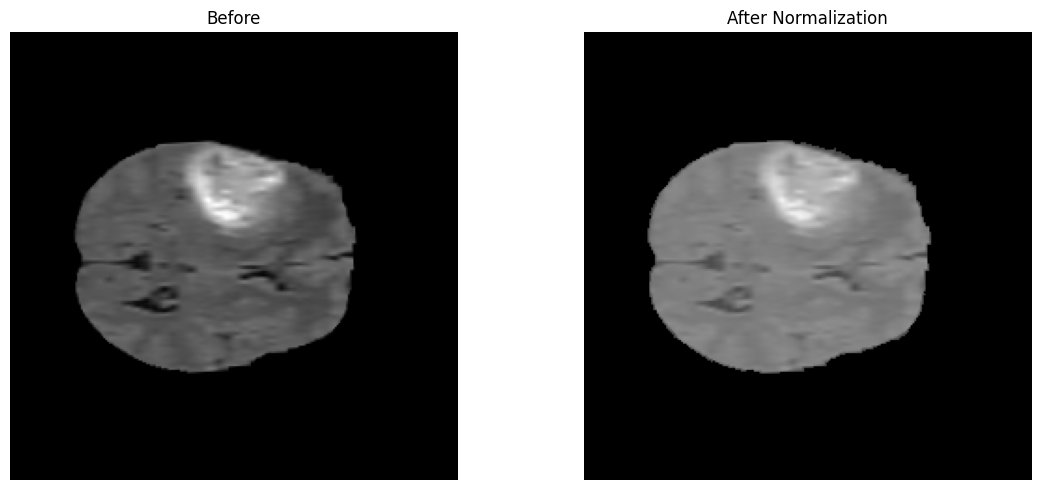

In [16]:
image_nii = nib.load(DATA_ROOT / train_df['image_relpath'][2])
label_nii = nib.load(DATA_ROOT / train_df['label_relpath'][2])

image_raw = torch.from_numpy(image_nii.get_fdata()).float()
label = torch.from_numpy(label_nii.get_fdata()).float()

print("Raw shape:", image_raw.shape)
print("Raw min/max:", image_raw.min().item(), image_raw.max().item())

# -------------------------
# After dataset preprocessing
# -------------------------

# Raw NIfTI: [H, W, D, C]
image_processed = torch.from_numpy(
    image_nii.get_fdata().copy()
).float()

# -> [C, D, H, W]
image_processed = torch.permute(
    image_processed, (3, 2, 0, 1)
)

# [H, W, D] -> [D, H, W]
label = torch.permute(label, (2, 0, 1))

# [D, H, W] -> [1, D, H, W]
label = label.unsqueeze(0)

# Preserve the original brain mask for reporting, then normalize.
brain_masks = image_processed != 0
image_processed = normalize_image(image_processed)

print("Processed shape:", image_processed.shape)
print(
    "Processed min/max:",
    image_processed.min().item(),
    image_processed.max().item()
)

print("\nPost-normalization statistics (non-zero brain voxels):")
for channel, name in enumerate(modalities):
    brain = brain_masks[channel]
    channel_values = image_processed[channel][brain]
    print(
        f"{name:5s}: mean={channel_values.mean().item(): .4f}, "
        f"std={channel_values.std(unbiased=False).item():.4f}"
    )


# -------------------------
# Display
# -------------------------

modality = 0
slice_idx = image_raw.shape[2] // 2

# Raw is [H, W, D, C]
before = image_raw[:, :, slice_idx, modality]

# Processed is [C, D, H, W]
after = image_processed[modality, slice_idx]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(before, cmap="gray")
ax[0].set_title("Before")
ax[0].axis("off")

after_np = after.cpu().numpy()
masked = np.ma.masked_where(after_np == 0, after_np)

cmap = plt.cm.gray.copy()
cmap.set_bad("black")
v = float(image_processed[modality].abs().max()) or 1.0

ax[1].imshow(masked, cmap=cmap, vmin=-v, vmax=v)
# ax[1].imshow(after, cmap="gray", vmin=-v, vmax=v)
ax[1].set_title("After Normalization")
ax[1].axis("off")

plt.tight_layout()
plt.show()

### Consistent crop/pad and safe augmentation

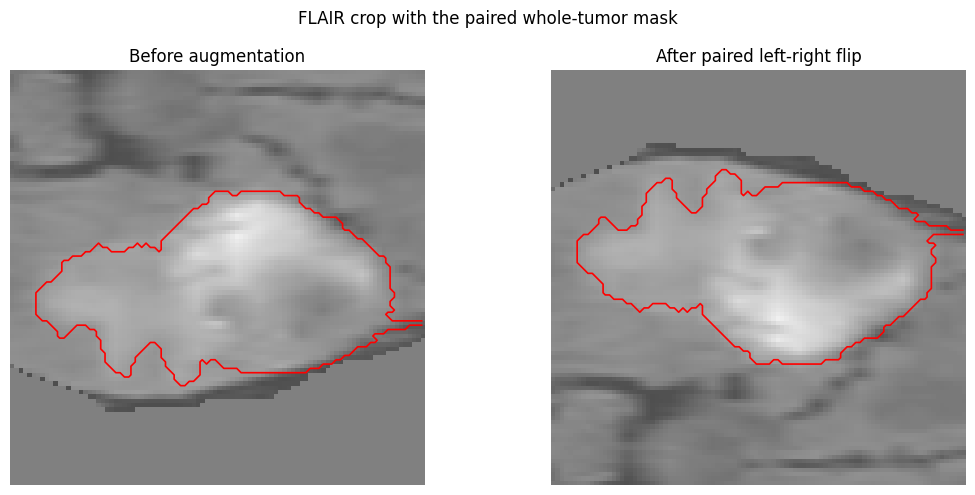

Before shapes: torch.Size([4, 96, 96, 96]) torch.Size([1, 96, 96, 96])
After shapes:  torch.Size([4, 96, 96, 96]) torch.Size([1, 96, 96, 96])
Mask values after augmentation: [0.0, 1.0]


In [17]:
# Build a tumor-centred crop so the paired augmentation is easy to inspect.
example_image, example_mask = train_dataset._load_case(0)
tumor_coordinates = torch.nonzero(example_mask[0] > 0, as_tuple=False)
tumor_centre = tumor_coordinates.float().mean(dim=0).round().long()

crop_start = []
for centre, size, patch in zip(
    tumor_centre.tolist(), example_image.shape[1:], PATCH_SIZE
):
    crop_start.append(max(0, min(centre - patch // 2, size - patch)))

before_image, before_mask = train_dataset._extract_patch(
    example_image, example_mask, *crop_start
)

# Force the same safe transform used in training so it is visible here.
after_image, after_mask = augment(
    before_image.clone(), before_mask.clone(), probability=1.0
)

slice_idx = int(before_mask[0].sum(dim=(1, 2)).argmax())
channel = 0  # FLAIR
v = float(before_image[channel].abs().max()) or 1.0

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
paired = [
    (before_image, before_mask, "Before augmentation"),
    (after_image, after_mask, "After paired left-right flip"),
]

for ax, (patch_image, patch_mask, title) in zip(axes, paired):
    image_slice = patch_image[channel, slice_idx].cpu().numpy()
    mask_slice = patch_mask[0, slice_idx].cpu().numpy()
    ax.imshow(image_slice, cmap="gray", vmin=-v, vmax=v)
    ax.contour(mask_slice, levels=[0.5], colors="red", linewidths=1.2)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("FLAIR crop with the paired whole-tumor mask")
plt.tight_layout()
plt.show()

print("Before shapes:", before_image.shape, before_mask.shape)
print("After shapes: ", after_image.shape, after_mask.shape)
print("Mask values after augmentation:", torch.unique(after_mask).tolist())

In [18]:
#single batch shape

train_batch = next(iter(train_loader))
val_batch = next(iter(val_loader))

print("Train:")
print("  Images:", train_batch["image"].shape)
print("  Masks: ", train_batch["mask"].shape)

print("\nValidation:")
print("  Images:", val_batch["image"].shape)
print("  Masks: ", val_batch["mask"].shape)

Train:
  Images: torch.Size([4, 4, 96, 96, 96])
  Masks:  torch.Size([4, 1, 96, 96, 96])

Validation:
  Images: torch.Size([4, 4, 96, 96, 96])
  Masks:  torch.Size([4, 1, 96, 96, 96])


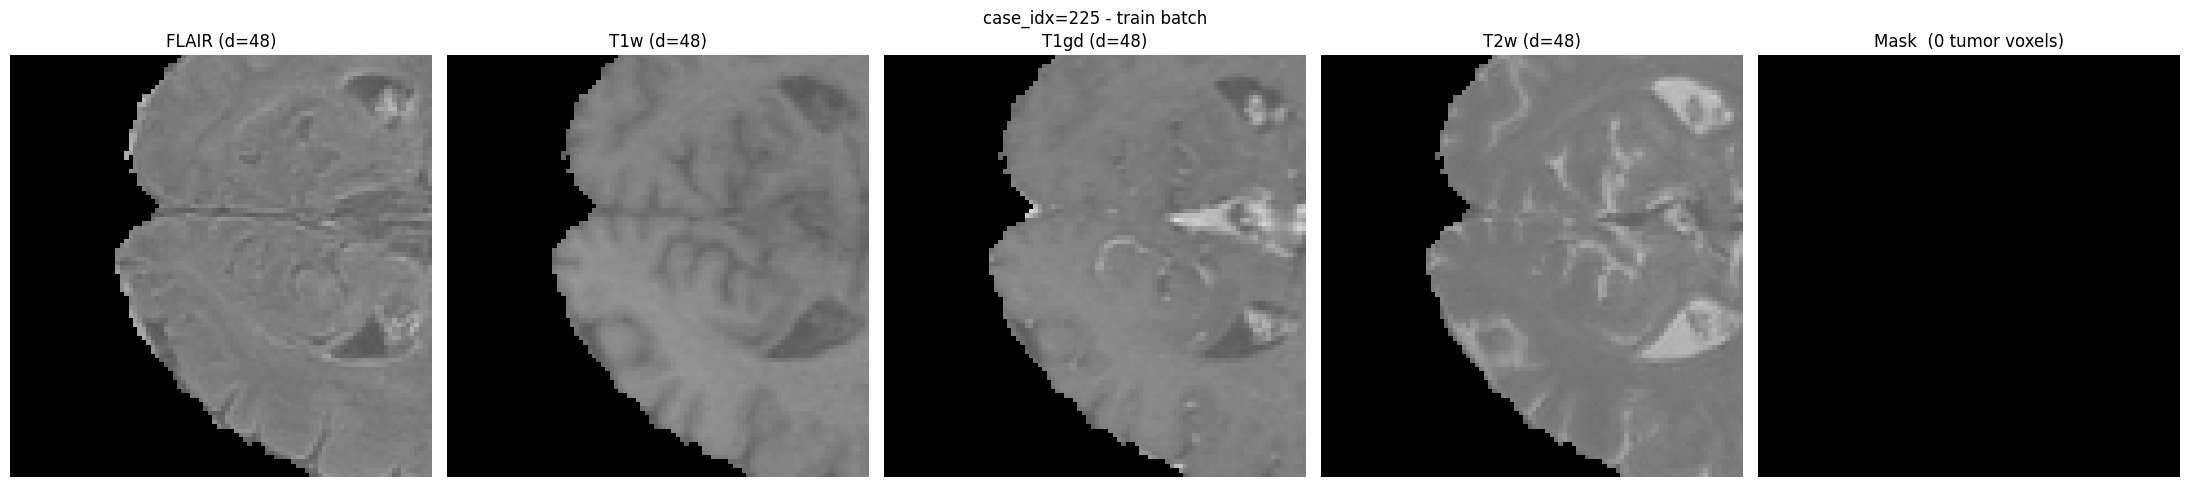

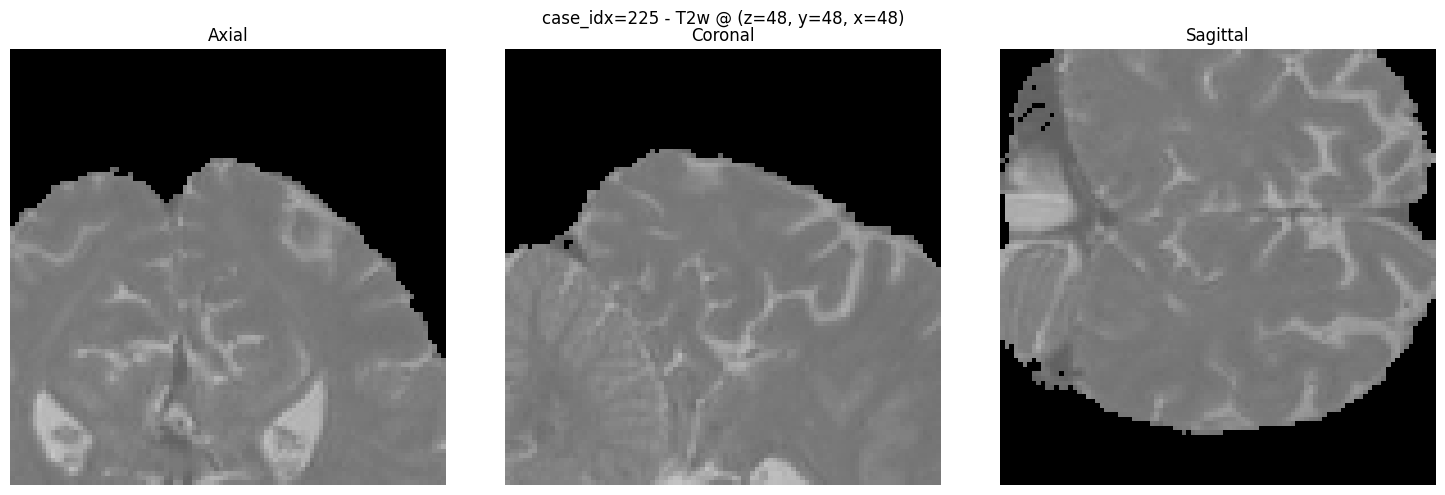

In [19]:
def _to_numpy(t):
    """Detach a tensor and move it to CPU as a numpy array."""
    return t.detach().cpu().numpy()


def _best_slice(mask_3d):
    """
    Pick the axial slice with the most tumor.

    Returns the middle slice if the patch is all background (common for
    sliding-window validation patches).
    """
    if mask_3d.sum() == 0:
        return mask_3d.shape[0] // 2
    return int(mask_3d.sum(axis=(1, 2)).argmax())


def _gray_with_background():
    """Grayscale colormap where masked-out voxels render as black."""
    cmap = plt.cm.gray.copy()
    cmap.set_bad("black")
    return cmap


def show_case(image, mask, case_idx, d=None, title=""):
    """
    All 4 modalities + the mask for one item of a batch, with a red
    whole-tumor contour overlaid.

    image: [C, D, H, W]
    mask:  [1, D, H, W]
    """
    image = _to_numpy(image)
    mask = _to_numpy(mask)[0]  # -> [D, H, W]

    if d is None:
        d = _best_slice(mask)

    v = float(np.abs(image).max()) or 1.0
    cmap = _gray_with_background()

    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    for ax, name, c in zip(axes[:4], list(modalities.keys()), range(image.shape[0])):
        sl = image[c, d]
        ax.imshow(np.ma.masked_where(sl == 0, sl), cmap=cmap, vmin=-v, vmax=v)
        ax.contour(mask[d], levels=[0.5], colors="red", linewidths=1.2)
        ax.set_title(f"{name} (d={d})")
        ax.axis("off")

    axes[4].imshow(mask[d], cmap="gray")
    axes[4].set_title(f"Mask  ({mask.sum():.0f} tumor voxels)")
    axes[4].axis("off")

    fig.suptitle(f"case_idx={case_idx} - {title}")
    plt.tight_layout()
    plt.show()


def show_ortho(image, mask, case_idx, channel=3):
    """
    Axial / coronal / sagittal views through the tumor centre.

    image: [C, D, H, W]
    mask:  [1, D, H, W]
    channel: modality index (3 = T2w)
    """
    image = _to_numpy(image)
    mask = _to_numpy(mask)[0]

    if mask.sum() > 0:
        z, y, x = np.rint(np.argwhere(mask > 0).mean(axis=0)).astype(int)
    else:
        z, y, x = [s // 2 for s in mask.shape]

    v = float(np.abs(image).max()) or 1.0
    cmap = _gray_with_background()

    img = image[channel]

    views = [
        ("Axial", img[z], mask[z]),
        ("Coronal", img[:, y, :], mask[:, y, :]),
        ("Sagittal", img[:, :, x], mask[:, :, x]),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (name, sl, msk) in zip(axes, views):
        ax.imshow(np.ma.masked_where(sl.T == 0, sl.T), cmap=cmap, vmin=-v, vmax=v)
        ax.contour(msk.T, levels=[0.5], colors="red", linewidths=1.2)
        ax.set_title(name)
        ax.axis("off")

    fig.suptitle(f"case_idx={case_idx} - {list(modalities.keys())[channel]} @ (z={z}, y={y}, x={x})")
    plt.tight_layout()
    plt.show()


def show_batch(batch, title="batch", b=0):
    """show_case() for one specific item of a batch."""
    show_case(
        batch["image"][b],
        batch["mask"][b],
        batch["case_idx"][b],
        title=title,
    )


def show_batch_grid(batch, title="batch"):
    """
    Rows = items in the batch, columns = the 4 modalities.
    Each panel uses that item's own tumor-heavy slice.
    """
    img_all = _to_numpy(batch["image"])  # [B, C, D, H, W]
    msk_all = _to_numpy(batch["mask"])[:, 0]  # [B, D, H, W]

    n = img_all.shape[0]
    fig, axes = plt.subplots(n, 4, figsize=(18, 4.5 * n), squeeze=False)

    for b in range(n):
        img = img_all[b]
        msk = msk_all[b]
        d = _best_slice(msk)
        v = float(np.abs(img).max()) or 1.0
        cmap = _gray_with_background()

        for c in range(4):
            ax = axes[b, c]
            sl = img[c, d]
            ax.imshow(np.ma.masked_where(sl == 0, sl), cmap=cmap, vmin=-v, vmax=v)
            ax.contour(msk[d], levels=[0.5], colors="red", linewidths=1.0)
            ax.set_title(f"b{b} {list(modalities.keys())[c]}")
            ax.axis("off")

    fig.suptitle(f"{title} - 4 modalities x {n} items")
    plt.tight_layout()
    plt.show()

show_batch(train_batch, title="train batch", b=0)
show_ortho(train_batch["image"][0], train_batch["mask"][0], train_batch["case_idx"][0])
# show_batch_grid(train_batch, title="train batch")

## Training

In [20]:
import copy
import random
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

# Controlled experiment configuration
SEED = 42
INPUT_CHANNELS = 4
OUTPUT_CHANNELS = 1
BASE_CHANNELS = 8
TRAIN_BATCH_SIZE = 1
EPOCHS = 10
TRAIN_STEPS_PER_EPOCH = 50
ITERATION_BUDGET = EPOCHS * TRAIN_STEPS_PER_EPOCH
VALIDATION_PATCHES = 64
LEARNING_RATE = 1e-3
TUMOR_SAMPLING_PROBABILITY = 0.75
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class ConvBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv3d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels),
            nn.LeakyReLU(0.1, inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class LightweightUNet3D(nn.Module):
    """Two-level fully convolutional 3D U-Net for binary segmentation."""
    def __init__(self, in_channels=4, out_channels=1, base_channels=8):
        super().__init__()
        b = base_channels
        self.enc1 = ConvBlock3D(in_channels, b)
        self.enc2 = ConvBlock3D(b, 2 * b)
        self.bottleneck = ConvBlock3D(2 * b, 4 * b)
        self.pool = nn.MaxPool3d(2)
        self.up2 = nn.ConvTranspose3d(4 * b, 2 * b, 2, stride=2)
        self.dec2 = ConvBlock3D(4 * b, 2 * b)
        self.up1 = nn.ConvTranspose3d(2 * b, b, 2, stride=2)
        self.dec1 = ConvBlock3D(2 * b, b)
        self.output = nn.Conv3d(b, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        bottleneck = self.bottleneck(self.pool(e2))
        d2 = self.dec2(torch.cat([self.up2(bottleneck), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output(d1)


set_seed(SEED)
initial_model = LightweightUNet3D(
    INPUT_CHANNELS, OUTPUT_CHANNELS, BASE_CHANNELS
)
INITIAL_STATE = copy.deepcopy(initial_model.state_dict())
PARAMETER_COUNT = sum(p.numel() for p in initial_model.parameters() if p.requires_grad)

print(f"Input channels: {INPUT_CHANNELS}")
print(f"Output channels: {OUTPUT_CHANNELS}")
print(f"Trainable parameters: {PARAMETER_COUNT:,}")
print(f"Patch size: {PATCH_SIZE}")
print(f"Seed: {SEED}")
print(f"Budget per sampler: {EPOCHS} epochs x {TRAIN_STEPS_PER_EPOCH} steps = {ITERATION_BUDGET} updates")

Device: cuda
GPU: NVIDIA RTX 5000 Ada Generation
Input channels: 4
Output channels: 1
Trainable parameters: 85,825
Patch size: (96, 96, 96)
Seed: 42
Budget per sampler: 10 epochs x 50 steps = 500 updates


In [21]:
class TrainingPatchDataset(BraTSPatchDataset):
    """Training dataset supporting controlled uniform/tumor-aware crops."""
    def __init__(self, *args, sampling="uniform", tumor_probability=0.75, **kwargs):
        super().__init__(*args, train=True, **kwargs)
        if sampling not in {"uniform", "tumor_aware"}:
            raise ValueError("sampling must be 'uniform' or 'tumor_aware'")
        self.sampling = sampling
        self.tumor_probability = tumor_probability
        self.sampled_patches = 0
        self.tumor_patches = 0

    @staticmethod
    def _start_containing(voxel, size, patch):
        low = max(0, voxel - patch + 1)
        high = min(voxel, size - patch)
        return np.random.randint(low, high + 1)

    def _random_patch(self, image, label):
        _, D, H, W = image.shape
        pd, ph, pw = self.patch_size
        choose_tumor = (
            self.sampling == "tumor_aware"
            and label.any().item()
            and np.random.random() < self.tumor_probability
        )

        if choose_tumor:
            tumor_voxels = torch.nonzero(label[0] > 0, as_tuple=False)
            voxel = tumor_voxels[np.random.randint(len(tumor_voxels))].tolist()
            d = self._start_containing(voxel[0], D, pd)
            h = self._start_containing(voxel[1], H, ph)
            w = self._start_containing(voxel[2], W, pw)
        else:
            d = np.random.randint(0, D - pd + 1)
            h = np.random.randint(0, H - ph + 1)
            w = np.random.randint(0, W - pw + 1)

        patches = self._extract_patch(image, label, d, h, w)
        return patches, (d, h, w)

    def __getitem__(self, idx):
        sample = super().__getitem__(idx)
        self.sampled_patches += 1
        self.tumor_patches += int(sample["mask"].any().item())
        return sample

    @property
    def tumor_patch_fraction(self):
        return self.tumor_patches / max(self.sampled_patches, 1)


uniform_train_dataset = TrainingPatchDataset(
    train_df, DATA_ROOT, patch_size=PATCH_SIZE, sampling="uniform"
)
tumor_train_dataset = TrainingPatchDataset(
    train_df, DATA_ROOT, patch_size=PATCH_SIZE, sampling="tumor_aware",
    tumor_probability=TUMOR_SAMPLING_PROBABILITY,
)

# Fixed, evenly spaced validation patches are shared by both experiments.
validation_indices = np.linspace(
    0, len(val_dataset) - 1, min(VALIDATION_PATCHES, len(val_dataset)), dtype=int
).tolist()
fixed_validation_dataset = Subset(val_dataset, validation_indices)
validation_loader = DataLoader(
    fixed_validation_dataset, batch_size=1, shuffle=False, num_workers=4,
    pin_memory=(DEVICE.type == "cuda"),
)

In [22]:
class BCEDiceLoss(nn.Module):
    """Equal-weight binary cross-entropy and soft Dice loss."""
    def __init__(self, smooth=1e-5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.smooth = smooth

    def forward(self, logits, targets):
        probabilities = torch.sigmoid(logits)
        dims = tuple(range(1, targets.ndim))
        intersection = (probabilities * targets).sum(dim=dims)
        denominator = probabilities.sum(dim=dims) + targets.sum(dim=dims)
        dice_loss = 1 - ((2 * intersection + self.smooth) / (denominator + self.smooth)).mean()
        return 0.5 * self.bce(logits, targets) + 0.5 * dice_loss


def binary_dice_counts(logits, targets, threshold=0.5):
    predictions = (torch.sigmoid(logits) >= threshold).float()
    intersection = (predictions * targets).sum().item()
    predicted = predictions.sum().item()
    target = targets.sum().item()
    return intersection, predicted, target


@torch.no_grad()
def validate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_intersection = total_predicted = total_target = 0.0

    for batch in loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)
        logits = model(images)
        total_loss += criterion(logits, masks).item()
        intersection, predicted, target = binary_dice_counts(logits, masks)
        total_intersection += intersection
        total_predicted += predicted
        total_target += target

    mean_loss = total_loss / len(loader)
    dice = (2 * total_intersection + 1e-5) / (total_predicted + total_target + 1e-5)
    return mean_loss, dice


def train_experiment(name, dataset):
    # Identical seed, initialization, optimizer and update budget for both samplers.
    set_seed(SEED)
    dataset.sampled_patches = 0
    dataset.tumor_patches = 0
    total_sampled_patches = 0
    total_tumor_patches = 0

    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(
        dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, num_workers=4,
        pin_memory=(DEVICE.type == "cuda"), generator=generator,
    )

    model = LightweightUNet3D(INPUT_CHANNELS, OUTPUT_CHANNELS, BASE_CHANNELS)
    model.load_state_dict(copy.deepcopy(INITIAL_STATE))
    model = model.to(DEVICE)
    criterion = BCEDiceLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "val_loss": [], "val_dice": []}
    best_dice = -1.0
    best_state = None

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        iterator = iter(loader)

        for _ in range(TRAIN_STEPS_PER_EPOCH):
            try:
                batch = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                batch = next(iterator)

            images = batch["image"].to(DEVICE, non_blocking=True)
            masks = batch["mask"].to(DEVICE, non_blocking=True)

            # Count the masks that actually enter training. This works with
            # any batch size and with multiple DataLoader worker processes.
            contains_tumor = masks.flatten(start_dim=1).any(dim=1)
            total_sampled_patches += masks.shape[0]
            total_tumor_patches += contains_tumor.sum().item()
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        train_loss = running_loss / TRAIN_STEPS_PER_EPOCH
        val_loss, val_dice = validate(model, validation_loader, criterion)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        if val_dice > best_dice:
            best_dice = val_dice
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            checkpoint_path = MODEL_DIR / f"{name.replace('-', '_')}_best.pt"
            torch.save({
                "sampler": name,
                "epoch": epoch + 1,
                "best_val_dice": best_dice,
                "model_state_dict": best_state,
                "input_channels": INPUT_CHANNELS,
                "output_channels": OUTPUT_CHANNELS,
                "base_channels": BASE_CHANNELS,
                "patch_size": PATCH_SIZE,
                "seed": SEED,
            }, checkpoint_path)

        print(
            f"{name:11s} | epoch {epoch + 1}/{EPOCHS} | "
            f"train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
            f"val Dice {val_dice:.4f}"
        )

    model.load_state_dict(best_state)  # selected using validation Dice only
    tumor_fraction = total_tumor_patches / max(total_sampled_patches, 1)

    # Copy the main-process totals back for the summary table below.
    dataset.sampled_patches = total_sampled_patches
    dataset.tumor_patches = total_tumor_patches

    print(f"{name} tumor-containing patch fraction: {tumor_fraction:.3f}")
    return model, history, tumor_fraction


print("Loss: 0.5 * BCEWithLogitsLoss + 0.5 * soft Dice loss")
print(f"Optimizer: Adam | learning rate: {LEARNING_RATE}")
print(f"Seed: {SEED} | update budget per run: {ITERATION_BUDGET}")

Loss: 0.5 * BCEWithLogitsLoss + 0.5 * soft Dice loss
Optimizer: Adam | learning rate: 0.001
Seed: 42 | update budget per run: 500


In [23]:
# # Run the controlled experiments. The test split is not accessed here.
# uniform_model, uniform_history, uniform_tumor_fraction = train_experiment(
#     "uniform", uniform_train_dataset
# )
# tumor_model, tumor_history, tumor_aware_fraction = train_experiment(
#     "tumor-aware", tumor_train_dataset
# )

# sampling_results = pd.DataFrame({
#     "sampler": ["uniform", "tumor-aware"],
#     "sampled_patches": [
#         uniform_train_dataset.sampled_patches,
#         tumor_train_dataset.sampled_patches,
#     ],
#     "fraction_containing_tumor": [
#         uniform_tumor_fraction, tumor_aware_fraction,
#     ],
# })
# display(sampling_results)

# # Select between the two controlled runs using validation Dice only.
# experiment_results = {
#     "uniform": (uniform_model, uniform_history),
#     "tumor-aware": (tumor_model, tumor_history),
# }
# best_sampler = max(
#     experiment_results,
#     key=lambda name: max(experiment_results[name][1]["val_dice"]),
# )
# best_model, best_history = experiment_results[best_sampler]
# best_epoch = int(np.argmax(best_history["val_dice"])) + 1
# best_val_dice = float(max(best_history["val_dice"]))
# best_model_state = {
#     key: value.detach().cpu().clone()
#     for key, value in best_model.state_dict().items()
# }
# best_model_path = MODEL_DIR / "best_model.pt"
# torch.save({
#     "sampler": best_sampler,
#     "epoch": best_epoch,
#     "best_val_dice": best_val_dice,
#     "model_state_dict": best_model_state,
#     "input_channels": INPUT_CHANNELS,
#     "output_channels": OUTPUT_CHANNELS,
#     "base_channels": BASE_CHANNELS,
#     "patch_size": PATCH_SIZE,
#     "seed": SEED,
# }, best_model_path)
# print(
#     f"Saved overall best model to {best_model_path} "
#     f"({best_sampler}, epoch {best_epoch}, validation Dice={best_val_dice:.4f})"
# )

uniform     | epoch 1/10 | train loss 0.6607 | val loss 0.6302 | val Dice 0.7138
uniform     | epoch 2/10 | train loss 0.6034 | val loss 0.5826 | val Dice 0.6567
uniform     | epoch 3/10 | train loss 0.5288 | val loss 0.5347 | val Dice 0.7402
uniform     | epoch 4/10 | train loss 0.4977 | val loss 0.4908 | val Dice 0.8306
uniform     | epoch 5/10 | train loss 0.4652 | val loss 0.4576 | val Dice 0.8119
uniform     | epoch 6/10 | train loss 0.4154 | val loss 0.4297 | val Dice 0.8566
uniform     | epoch 7/10 | train loss 0.3950 | val loss 0.4073 | val Dice 0.7883
uniform     | epoch 8/10 | train loss 0.3616 | val loss 0.3883 | val Dice 0.7716
uniform     | epoch 9/10 | train loss 0.3283 | val loss 0.3672 | val Dice 0.7991
uniform     | epoch 10/10 | train loss 0.3650 | val loss 0.3446 | val Dice 0.8344
uniform tumor-containing patch fraction: 0.814
tumor-aware | epoch 1/10 | train loss 0.6135 | val loss 0.6358 | val Dice 0.5692
tumor-aware | epoch 2/10 | train loss 0.5163 | val loss 0.5899 | val Dice 0.5604
tumor-aware | epoch 3/10 | train loss 0.4450 | val loss 0.5402 | val Dice 0.6836
tumor-aware | epoch 4/10 | train loss 0.4251 | val loss 0.4904 | val Dice 0.7971
tumor-aware | epoch 5/10 | train loss 0.3465 | val loss 0.4584 | val Dice 0.7182
tumor-aware | epoch 6/10 | train loss 0.3146 | val loss 0.4178 | val Dice 0.8118
tumor-aware | epoch 7/10 | train loss 0.2765 | val loss 0.3989 | val Dice 0.7649
tumor-aware | epoch 8/10 | train loss 0.2474 | val loss 0.3873 | val Dice 0.7129
tumor-aware | epoch 9/10 | train loss 0.2211 | val loss 0.3602 | val Dice 0.7968
tumor-aware | epoch 10/10 | train loss 0.2383 | val loss 0.3668 | val Dice 0.7165
tumor-aware tumor-containing patch fraction: 0.954


In [24]:
# epochs = np.arange(1, EPOCHS + 1)
# fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# for name, history in [
#     ("Uniform", uniform_history),
#     ("Tumor-aware", tumor_history),
# ]:
#     axes[0].plot(epochs, history["train_loss"], marker="o", label=name)
#     axes[1].plot(epochs, history["val_loss"], marker="o", label=name)
#     axes[2].plot(epochs, history["val_dice"], marker="o", label=name)

# axes[0].set_title("Training loss")
# axes[1].set_title("Validation loss")
# axes[2].set_title("Validation Dice")
# axes[2].set_ylim(0, 1)
# for ax in axes:
#     ax.set_xlabel("Epoch")
#     ax.grid(alpha=0.3)
#     ax.legend()
# plt.tight_layout()
# plt.show()


# def diagnose_training(name, history):
#     train = np.asarray(history["train_loss"])
#     val = np.asarray(history["val_loss"])
#     dice = np.asarray(history["val_dice"])
#     best_epoch = int(dice.argmax()) + 1

#     if len(val) > 2 and np.std(np.diff(val)) > 0.15 * max(abs(val.mean()), 1e-8):
#         diagnosis = "training appears unstable because validation loss fluctuates strongly"
#     elif val[-1] > val.min() * 1.10 and train[-1] < train[0] * 0.80:
#         diagnosis = "possible overfitting: training loss fell while validation loss rose from its minimum"
#     elif dice.max() < 0.30 and train[-1] > 0.50:
#         diagnosis = "likely underfitting at this budget: both loss and validation Dice remain weak"
#     else:
#         diagnosis = "no clear instability or overfitting signal within this training budget"

#     print(
#         f"{name}: best validation Dice={dice.max():.4f} at epoch {best_epoch}; "
#         f"{diagnosis}."
#     )


# diagnose_training("Uniform", uniform_history)
# diagnose_training("Tumor-aware", tumor_history)
# print("Model selection and diagnosis used validation metrics only; test results were not used.")

## Evaluate

### Uniform and Tumor Aware

In [25]:
def load_model(path):
    model = LightweightUNet3D(
        INPUT_CHANNELS, OUTPUT_CHANNELS, BASE_CHANNELS
    )

    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    return model


uniform_model = load_model(MODEL_DIR / "uniform_best.pt")
tumor_model = load_model(MODEL_DIR / "tumor_aware_best.pt")

In [26]:
import time
from scipy.ndimage import binary_erosion, distance_transform_edt


def compute_hd95_mm(prediction, target, spacing_dhw):
    """Calculate symmetric HD95 between binary masks in millimetres.

    Parameters
    ----------
    prediction, target : array-like, shape (D, H, W)
        Binary segmentation masks.
    spacing_dhw : tuple
        Physical voxel spacing corresponding to the array axes (D, H, W).

    Returns
    -------
    float
        Symmetric 95th-percentile Hausdorff distance. Returns:
        - 0.0 if both masks are empty
        - np.inf if exactly one mask is empty
    """
    prediction = np.asarray(prediction, dtype=bool)
    target = np.asarray(target, dtype=bool)

    prediction_nonempty = prediction.any()
    target_nonempty = target.any()

    if not prediction_nonempty and not target_nonempty:
        return 0.0

    if prediction_nonempty != target_nonempty:
        return np.inf

    structure = np.ones((3, 3, 3), dtype=bool)

    prediction_surface = prediction & ~binary_erosion(
        prediction, structure=structure, border_value=0
    )
    target_surface = target & ~binary_erosion(
        target, structure=structure, border_value=0
    )

    # Each distance map gives the physical distance to the nearest surface voxel.
    distance_to_target = distance_transform_edt(
        ~target_surface, sampling=spacing_dhw
    )
    distance_to_prediction = distance_transform_edt(
        ~prediction_surface, sampling=spacing_dhw
    )

    prediction_to_target = distance_to_target[prediction_surface]
    target_to_prediction = distance_to_prediction[target_surface]

    surface_distances = np.concatenate(
        [prediction_to_target, target_to_prediction]
    )
    return float(np.percentile(surface_distances, 95))


@torch.inference_mode()
def evaluate_validation_model(
    model,
    dataset,
    model_name,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
    postprocess_fn=None,
    postprocess_kwargs=None,
):
    """Reconstruct volumes and calculate case-level whole-tumor metrics.

    If postprocess_fn is supplied, it is applied to the thresholded 3D
    prediction before all metrics and volumes are calculated.
    """
    device = torch.device(device)
    model = model.to(device)
    model.eval()

    if postprocess_kwargs is None:
        postprocess_kwargs = {}

    rows = []
    patch_d, patch_h, patch_w = dataset.patch_size
    use_amp = device.type == "cuda"

    for case_idx in range(len(dataset.df)):
        start_time = time.perf_counter()

        image, target = dataset._load_case(case_idx)
        _, D, H, W = image.shape

        d_starts = dataset._get_starts(
            D, patch_d, dataset.stride[0]
        )
        h_starts = dataset._get_starts(
            H, patch_h, dataset.stride[1]
        )
        w_starts = dataset._get_starts(
            W, patch_w, dataset.stride[2]
        )

        locations = [
            (d, h, w)
            for d in d_starts
            for h in h_starts
            for w in w_starts
        ]

        probability_sum = torch.zeros(
            (1, D, H, W),
            dtype=torch.float32,
        )
        prediction_count = torch.zeros_like(probability_sum)

        for start in range(0, len(locations), batch_size):
            location_batch = locations[start:start + batch_size]

            image_batch = torch.stack([
                dataset._extract_patch(
                    image, target, d, h, w
                )[0]
                for d, h, w in location_batch
            ]).to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp,
            ):
                probabilities = torch.sigmoid(
                    model(image_batch)
                )

            probabilities = probabilities.float().cpu()

            for probability, (d, h, w) in zip(
                probabilities,
                location_batch,
            ):
                probability_sum[
                    :,
                    d:d + patch_d,
                    h:h + patch_h,
                    w:w + patch_w,
                ] += probability

                prediction_count[
                    :,
                    d:d + patch_d,
                    h:h + patch_h,
                    w:w + patch_w,
                ] += 1

        mean_probability = probability_sum.div(
            prediction_count.clamp_min(1)
        )

        prediction = mean_probability.ge(threshold)
        target_binary = target.ge(0.5)

        # Save the number of positive voxels before postprocessing.
        predicted_voxels_before_postprocessing = int(
            prediction.sum().item()
        )

        # Apply optional connected-component postprocessing.
        if postprocess_fn is not None:
            prediction_np = (
                prediction.squeeze(0)
                .cpu()
                .numpy()
                .astype(bool)
            )

            prediction_np = postprocess_fn(
                prediction_np,
                **postprocess_kwargs,
            )

            prediction = torch.from_numpy(
                prediction_np
            ).bool().unsqueeze(0)

        true_positive = int(
            torch.logical_and(
                prediction, target_binary
            ).sum().item()
        )
        false_positive = int(
            torch.logical_and(
                prediction, ~target_binary
            ).sum().item()
        )
        false_negative = int(
            torch.logical_and(
                ~prediction, target_binary
            ).sum().item()
        )
        true_negative = int(
            torch.logical_and(
                ~prediction, ~target_binary
            ).sum().item()
        )

        predicted_voxels = int(prediction.sum().item())
        reference_voxels = int(target_binary.sum().item())
        empty_prediction = predicted_voxels == 0

        removed_voxels = (
            predicted_voxels_before_postprocessing
            - predicted_voxels
        )

        dice_denominator = (
            2 * true_positive
            + false_positive
            + false_negative
        )
        iou_denominator = (
            true_positive
            + false_positive
            + false_negative
        )
        sensitivity_denominator = (
            true_positive + false_negative
        )

        dice = (
            2 * true_positive / dice_denominator
            if dice_denominator > 0
            else 1.0
        )

        iou = (
            true_positive / iou_denominator
            if iou_denominator > 0
            else 1.0
        )

        sensitivity = (
            true_positive / sensitivity_denominator
            if sensitivity_denominator > 0
            else np.nan
        )

        row = dataset.df.iloc[case_idx]
        label_nii = nib.load(
            dataset.root_dir / row["label_relpath"]
        )

        spacing_xyz = tuple(
            float(value)
            for value in label_nii.header.get_zooms()[:3]
        )
        spacing_dhw = spacing_xyz[::-1]
        voxel_volume_mm3 = float(np.prod(spacing_xyz))

        prediction_np = (
            prediction.squeeze(0).numpy().astype(bool)
        )
        target_np = (
            target_binary.squeeze(0).numpy().astype(bool)
        )

        hd95_mm = compute_hd95_mm(
            prediction_np,
            target_np,
            spacing_dhw=spacing_dhw,
        )

        predicted_volume_ml = (
            predicted_voxels
            * voxel_volume_mm3
            / 1000.0
        )
        reference_volume_ml = (
            reference_voxels
            * voxel_volume_mm3
            / 1000.0
        )

        signed_volume_error_ml = (
            predicted_volume_ml
            - reference_volume_ml
        )
        absolute_volume_error_ml = abs(
            signed_volume_error_ml
        )

        volume_error_percentage = (
            100.0
            * absolute_volume_error_ml
            / reference_volume_ml
            if reference_volume_ml > 0
            else np.nan
        )

        false_positive_volume_ml = (
            false_positive
            * voxel_volume_mm3
            / 1000.0
        )

        elapsed_time = (
            time.perf_counter() - start_time
        )

        rows.append({
            "model": model_name,
            "case_id": row["case_id"],
            "postprocessed": postprocess_fn is not None,

            "whole_tumor_dice": dice,
            "whole_tumor_iou": iou,
            "tumor_sensitivity": sensitivity,
            "hd95_mm": hd95_mm,

            "true_positive_voxels": true_positive,
            "false_positive_voxels": false_positive,
            "false_negative_voxels": false_negative,
            "true_negative_voxels": true_negative,

            "predicted_voxels_before_postprocessing":
                predicted_voxels_before_postprocessing,
            "postprocessing_removed_voxels":
                removed_voxels,

            "predicted_tumor_voxels": predicted_voxels,
            "reference_tumor_voxels": reference_voxels,
            "voxel_volume_mm3": voxel_volume_mm3,
            "predicted_tumor_volume_ml":
                predicted_volume_ml,
            "reference_tumor_volume_ml":
                reference_volume_ml,

            "signed_volume_error_ml":
                signed_volume_error_ml,
            "absolute_volume_error_ml":
                absolute_volume_error_ml,
            "absolute_volume_error_percentage":
                volume_error_percentage,

            "false_positive_volume_ml":
                false_positive_volume_ml,

            "empty_prediction": empty_prediction,
            "time_seconds": elapsed_time,
        })

        print(
            f"{model_name}: evaluated "
            f"{case_idx + 1}/{len(dataset.df)} cases",
            end="\r",
        )

    print()
    return pd.DataFrame(rows)


def summarize_validation_metrics(case_metrics):
    """Report mean, SD and median case-wise metrics per model."""
    metric_columns = [
        "whole_tumor_dice",
        "whole_tumor_iou",
        "tumor_sensitivity",
        "hd95_mm",
        "predicted_tumor_volume_ml",
        "reference_tumor_volume_ml",
        "absolute_volume_error_ml",
        "absolute_volume_error_percentage",
        "false_positive_volume_ml",
    ]

    rows = []

    for model_name, group in case_metrics.groupby(
        "model", sort=False
    ):
        summary = {
            "condition": model_name,
            "cases": len(group),
            "empty_predictions": int(group["empty_prediction"].sum()),
            "time_seconds": group["time_seconds"].sum(),
        }

        for column in metric_columns:
            # Replace infinite HD95 values before aggregation. These arise
            # when exactly one of the two masks is empty.
            values = group[column].replace(
                [np.inf, -np.inf], np.nan
            )

            summary[f"{column}_mean"] = values.mean()
            summary[f"{column}_std"] = values.std()
            summary[f"{column}_median"] = values.median()

        summary["nonfinite_hd95_cases"] = int(
            (~np.isfinite(group["hd95_mm"])).sum()
        )

        rows.append(summary)

    return pd.DataFrame(rows).set_index("condition")

# uniform_validation_metrics = evaluate_validation_model(
#     uniform_model, val_dataset, "uniform"
# )
# tumor_validation_metrics = evaluate_validation_model(
#     tumor_model, val_dataset, "tumor-aware"
# )
# validation_case_metrics = pd.concat(
#     [uniform_validation_metrics, tumor_validation_metrics], ignore_index=True
# )
# validation_summary = summarize_validation_metrics(validation_case_metrics)
# display(validation_summary.round(4))

In [27]:
# validation_summary.to_csv("output/validation_summary.csv")

## Evaluate Full

In [28]:
# stride_results = []

# for stride in [(96, 96, 96), (48, 48, 48), (24, 24, 24)]:
#     val_stride_dataset = BraTSPatchDataset(
#         val_df,
#         root_dir=DATA_ROOT,
#         patch_size=PATCH_SIZE,
#         stride=stride,
#         train=False,
#     )

#     result = evaluate_validation_model(
#         uniform_model,
#         val_stride_dataset,
#         f"stride {stride}"
#     )

#     stride_results.append(result)

# stride_results = pd.concat(stride_results, ignore_index=True)
# stride_summary = validation_summary = summarize_validation_metrics(stride_results)
# stride_summary.head()



In [29]:
import ast

# stride_summary["stride"] = (
#     stride_summary.index
#     .to_series()
#     .str.extract(r"\((\d+),")[0]
#     .astype(int)
# )
# stride_summary.to_csv("output/stride_summary.csv")

stride_summary = pd.read_csv("output/stride_summary.csv")
stride_summary.head()


,condition,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,...,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases,stride
0,"stride (96, 96, 96)",73,0,149.937910,0.745901,0.187726,0.820481,0.625456,0.210483,0.695606,...,27.154677,15.077,56.058898,128.174079,16.564203,26.543644,28.036825,14.765,0,96
1,"stride (48, 48, 48)",73,0,166.725005,0.764083,0.178813,0.823554,0.647108,0.204853,0.700035,...,23.267581,17.514,49.246567,106.106379,15.900771,20.560575,24.099145,11.362,0,48
2,"stride (24, 24, 24)",73,0,267.636054,0.770463,0.174251,0.835461,0.654454,0.201497,0.717417,...,22.097053,17.450,47.442326,99.591946,17.322423,18.256685,22.206720,10.148,0,24


In [30]:
stride_summary.columns

Index(['condition', 'cases', 'empty_predictions', 'time_seconds',
       'whole_tumor_dice_mean', 'whole_tumor_dice_std',
       'whole_tumor_dice_median', 'whole_tumor_iou_mean',
       'whole_tumor_iou_std', 'whole_tumor_iou_median',
       'tumor_sensitivity_mean', 'tumor_sensitivity_std',
       'tumor_sensitivity_median', 'hd95_mm_mean', 'hd95_mm_std',
       'hd95_mm_median', 'predicted_tumor_volume_ml_mean',
       'predicted_tumor_volume_ml_std', 'predicted_tumor_volume_ml_median',
       'reference_tumor_volume_ml_mean', 'reference_tumor_volume_ml_std',
       'reference_tumor_volume_ml_median', 'absolute_volume_error_ml_mean',
       'absolute_volume_error_ml_std', 'absolute_volume_error_ml_median',
       'absolute_volume_error_percentage_mean',
       'absolute_volume_error_percentage_std',
       'absolute_volume_error_percentage_median',
       'false_positive_volume_ml_mean', 'false_positive_volume_ml_std',
       'false_positive_volume_ml_median', 'nonfinite_hd95_cases'

In [31]:
val_dataset = BraTSPatchDataset(
    val_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=(48, 48, 48),
    train=False,
)

#### Some plot

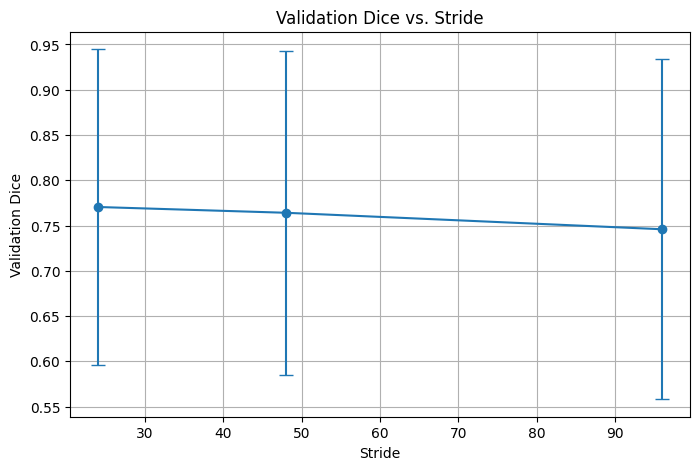

In [32]:
# Dice
plt.figure(figsize=(8, 5))
plt.errorbar(
    stride_summary["stride"],
    stride_summary["whole_tumor_dice_mean"],
    yerr=stride_summary["whole_tumor_dice_std"],
    marker="o",
    capsize=5,
)
plt.xlabel("Stride")
plt.ylabel("Validation Dice")
plt.title("Validation Dice vs. Stride")
plt.grid(True)
plt.show()

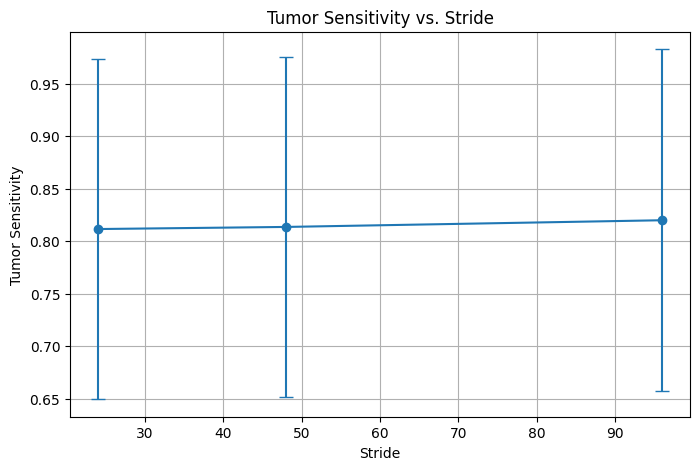

In [33]:
plt.figure(figsize=(8, 5))
plt.errorbar(
    stride_summary["stride"],
    stride_summary["tumor_sensitivity_mean"],
    yerr=stride_summary["tumor_sensitivity_std"],
    marker="o",
    capsize=5,
)
plt.xlabel("Stride")
plt.ylabel("Tumor Sensitivity")
plt.title("Tumor Sensitivity vs. Stride")
plt.grid(True)
plt.show()

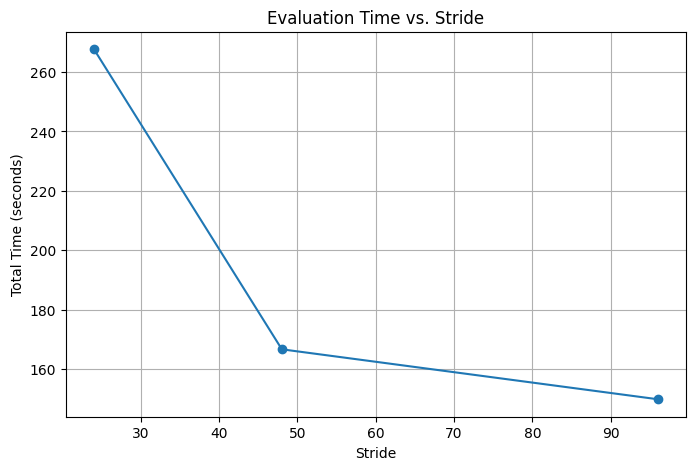

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(
    stride_summary["stride"],
    stride_summary["time_seconds"],
    marker="o",
)
plt.xlabel("Stride")
plt.ylabel("Total Time (seconds)")
plt.title("Evaluation Time vs. Stride")
plt.grid(True)
plt.show()

### Eval on Test

In [35]:
test_dataset = BraTSPatchDataset(
    test_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=(48, 48, 48),
    train=False,
)

# test_evaluation_result = evaluate_validation_model(
#     uniform_model, test_dataset, "uniform"
# )

In [36]:
# test_eval_summary = summarize_validation_metrics(test_evaluation_result)
# test_eval_summary.to_csv("output/test_eval_summary.csv")

test_eval_summary = pd.read_csv("output/test_eval_summary.csv")
test_eval_summary

,condition,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,...,absolute_volume_error_ml_mean,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases
0,uniform,73,0,168.389293,0.823833,0.122183,0.852417,0.715536,0.149817,0.742794,...,20.310055,23.821888,11.763,28.707534,86.227852,12.921277,12.409192,13.657858,8.083,0


In [37]:
import seaborn as sns


sns.set_theme(style="whitegrid", context="notebook")

def plot_evaluation_results(case_metrics):
    """Plot case-wise segmentation metrics for all evaluated models."""
    data = case_metrics.copy()

    # Infinite HD95 occurs when exactly one mask is empty. It cannot be
    # displayed on a finite axis, so replace it with NaN for plotting only.
    data["hd95_mm_plot"] = data["hd95_mm"].replace(
        [np.inf, -np.inf], np.nan
    )

    model_order = data["model"].drop_duplicates().tolist()

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 11),
        constrained_layout=True,
    )

    # 1. Dice
    sns.boxplot(
        data=data,
        x="model",
        y="whole_tumor_dice",
        order=model_order,
        showfliers=False,
        ax=axes[0, 0],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="whole_tumor_dice",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[0, 0],
    )
    axes[0, 0].set_title("Whole-tumor Dice")
    axes[0, 0].set_xlabel("")
    axes[0, 0].set_ylabel("Dice")
    axes[0, 0].set_ylim(0, 1.05)

    # 2. IoU
    sns.boxplot(
        data=data,
        x="model",
        y="whole_tumor_iou",
        order=model_order,
        showfliers=False,
        ax=axes[0, 1],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="whole_tumor_iou",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[0, 1],
    )
    axes[0, 1].set_title("Whole-tumor IoU")
    axes[0, 1].set_xlabel("")
    axes[0, 1].set_ylabel("IoU")
    axes[0, 1].set_ylim(0, 1.05)

    # 3. Sensitivity
    sns.boxplot(
        data=data,
        x="model",
        y="tumor_sensitivity",
        order=model_order,
        showfliers=False,
        ax=axes[0, 2],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="tumor_sensitivity",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[0, 2],
    )
    axes[0, 2].set_title("Tumor sensitivity")
    axes[0, 2].set_xlabel("")
    axes[0, 2].set_ylabel("Sensitivity")
    axes[0, 2].set_ylim(0, 1.05)

    # 4. HD95
    sns.boxplot(
        data=data,
        x="model",
        y="hd95_mm_plot",
        order=model_order,
        showfliers=False,
        ax=axes[1, 0],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="hd95_mm_plot",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[1, 0],
    )
    axes[1, 0].set_title("HD95")
    axes[1, 0].set_xlabel("")
    axes[1, 0].set_ylabel("HD95 (mm)")

    # 5. Absolute volume error
    sns.boxplot(
        data=data,
        x="model",
        y="absolute_volume_error_ml",
        order=model_order,
        showfliers=False,
        ax=axes[1, 1],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="absolute_volume_error_ml",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[1, 1],
    )
    axes[1, 1].set_title("Absolute tumor-volume error")
    axes[1, 1].set_xlabel("")
    axes[1, 1].set_ylabel("Absolute error (mL)")

    # 6. Percentage volume error
    sns.boxplot(
        data=data,
        x="model",
        y="absolute_volume_error_percentage",
        order=model_order,
        showfliers=False,
        ax=axes[1, 2],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="absolute_volume_error_percentage",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[1, 2],
    )
    axes[1, 2].set_title("Absolute percentage volume error")
    axes[1, 2].set_xlabel("")
    axes[1, 2].set_ylabel("Absolute error (%)")

    fig.suptitle(
        "Case-wise whole-tumor segmentation performance",
        fontsize=17,
        fontweight="bold",
    )

    plt.show()

plot_evaluation_results(test_evaluation_result)

NameError: name 'test_evaluation_result' is not defined

In [ ]:
def plot_casewise_dice(case_metrics):
    plot_data = case_metrics.pivot(
        index="case_id",
        columns="model",
        values="whole_tumor_dice",
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(max(12, len(plot_data) * 0.6), 6),
        width=0.8,
    )

    ax.set_title("Whole-tumor Dice by case")
    ax.set_xlabel("Case")
    ax.set_ylabel("Dice")
    ax.set_ylim(0, 1.05)
    ax.legend(title="Model")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()


plot_casewise_dice(stride_results)

NameError: name 'stride_results' is not defined

#### Helper

In [38]:
@torch.inference_mode()
def predict_full_case(
    model,
    dataset,
    case_idx,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
):
    """Reconstruct one full-volume prediction using sliding-window averaging."""
    device = torch.device(device)
    model = model.to(device)
    model.eval()

    image, target = dataset._load_case(case_idx)

    # Expected shapes:
    # image:  (C, D, H, W)
    # target: (1, D, H, W)
    _, D, H, W = image.shape
    patch_d, patch_h, patch_w = dataset.patch_size

    d_starts = dataset._get_starts(
        D, patch_d, dataset.stride[0]
    )
    h_starts = dataset._get_starts(
        H, patch_h, dataset.stride[1]
    )
    w_starts = dataset._get_starts(
        W, patch_w, dataset.stride[2]
    )

    locations = [
        (d, h, w)
        for d in d_starts
        for h in h_starts
        for w in w_starts
    ]

    probability_sum = torch.zeros(
        (1, D, H, W), dtype=torch.float32
    )
    prediction_count = torch.zeros_like(probability_sum)

    use_amp = device.type == "cuda"

    for start in range(0, len(locations), batch_size):
        location_batch = locations[start:start + batch_size]

        image_batch = torch.stack([
            dataset._extract_patch(image, target, d, h, w)[0]
            for d, h, w in location_batch
        ]).to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp,
        ):
            logits = model(image_batch)
            probabilities = torch.sigmoid(logits)

        probabilities = probabilities.float().cpu()

        for probability, (d, h, w) in zip(
            probabilities, location_batch
        ):
            probability_sum[
                :,
                d:d + patch_d,
                h:h + patch_h,
                w:w + patch_w,
            ] += probability

            prediction_count[
                :,
                d:d + patch_d,
                h:h + patch_h,
                w:w + patch_w,
            ] += 1

    probability = probability_sum / prediction_count.clamp_min(1)
    prediction = probability >= threshold
    target_binary = target >= 0.5

    return {
        "image": image.cpu(),
        "target": target_binary.cpu(),
        "probability": probability.cpu(),
        "prediction": prediction.cpu(),
    }

In [39]:
def plot_case_prediction(
    result,
    case_id=None,
    slice_idx=None,
    image_channel=0,
):
    """Compare an image slice, ground truth, and predicted tumor mask."""
    image = result["image"][image_channel].numpy()
    target = result["target"][0].numpy().astype(bool)
    prediction = result["prediction"][0].numpy().astype(bool)
    probability = result["probability"][0].numpy()

    if slice_idx is None:
        # Choose the axial slice containing the most ground-truth tumor.
        tumor_per_slice = target.sum(axis=(1, 2))

        if tumor_per_slice.max() > 0:
            slice_idx = int(np.argmax(tumor_per_slice))
        else:
            # If the ground truth is empty, use the slice with the largest
            # predicted tumor region.
            prediction_per_slice = prediction.sum(axis=(1, 2))

            if prediction_per_slice.max() > 0:
                slice_idx = int(np.argmax(prediction_per_slice))
            else:
                slice_idx = image.shape[0] // 2

    image_slice = image[slice_idx]
    target_slice = target[slice_idx]
    prediction_slice = prediction[slice_idx]
    probability_slice = probability[slice_idx]

    # Robust display range so extreme intensities do not dominate.
    finite_values = image_slice[np.isfinite(image_slice)]
    if finite_values.size:
        vmin, vmax = np.percentile(finite_values, [1, 99])
    else:
        vmin, vmax = 0, 1

    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    # Original scan
    axes[0].imshow(
        image_slice,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )
    axes[0].set_title("Input scan")

    # Ground-truth mask
    axes[1].imshow(
        target_slice,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1].set_title("Ground truth")

    # Predicted mask
    axes[2].imshow(
        prediction_slice,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[2].set_title("Predicted mask")

    # Probability map
    probability_plot = axes[3].imshow(
        probability_slice,
        cmap="magma",
        vmin=0,
        vmax=1,
    )
    axes[3].set_title("Tumor probability")
    fig.colorbar(
        probability_plot,
        ax=axes[3],
        fraction=0.046,
        pad=0.04,
    )

    # Overlay comparison
    axes[4].imshow(
        image_slice,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )

    # Green = ground truth, red = prediction.
    axes[4].imshow(
        np.ma.masked_where(~target_slice, target_slice),
        cmap="Greens",
        alpha=0.45,
        vmin=0,
        vmax=1,
    )
    axes[4].imshow(
        np.ma.masked_where(~prediction_slice, prediction_slice),
        cmap="Reds",
        alpha=0.45,
        vmin=0,
        vmax=1,
    )
    axes[4].set_title("Overlay: GT green, prediction red")

    for axis in axes:
        axis.axis("off")

    title = f"Case {case_id} — axial slice {slice_idx}"
    fig.suptitle(title, fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

#### Continue

In [40]:
val_df[val_df['case_id']=='BRATS_373']

,case_id,image_relpath,label_relpath,tumor_volume
59,BRATS_373,imagesTr/BRATS_373.nii.gz,labelsTr/BRATS_373.nii.gz,7285.0


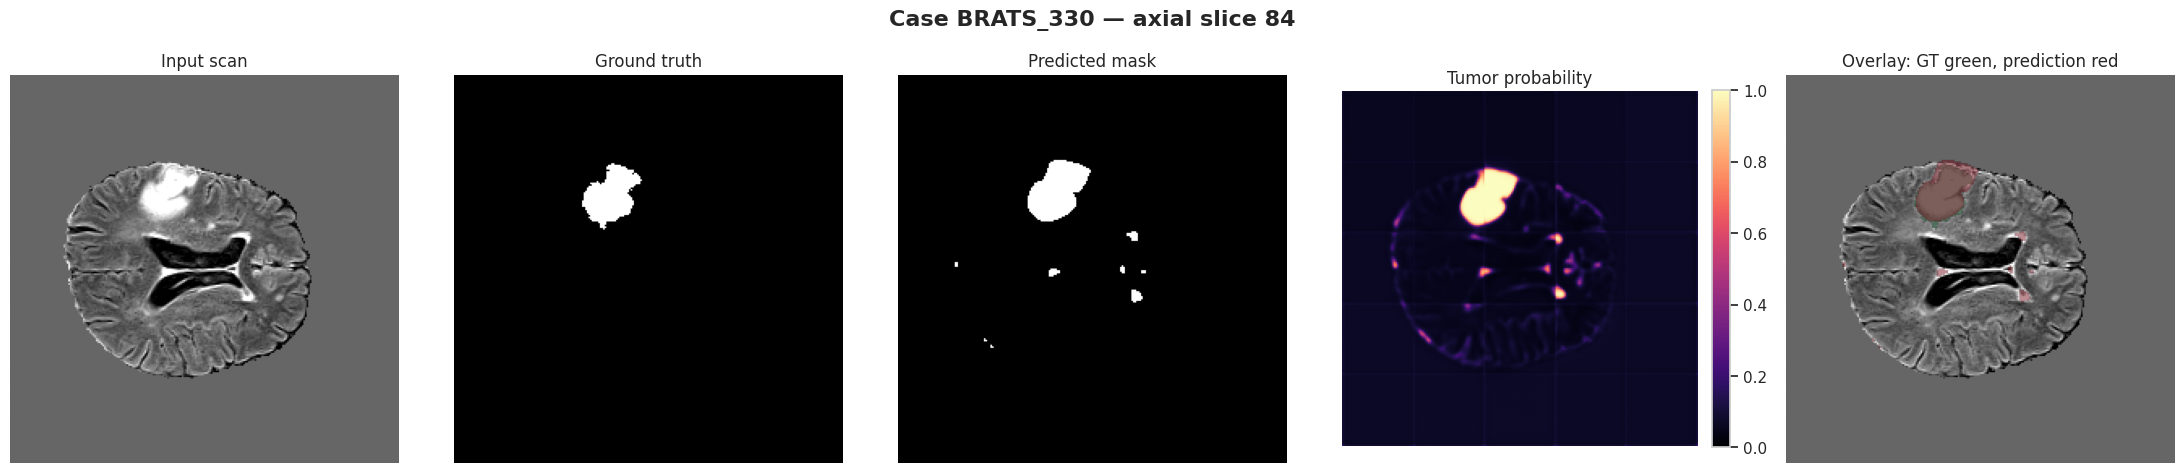

In [41]:
case_idx = 51
case_id = val_dataset.df.iloc[case_idx]["case_id"]

result = predict_full_case(
    model=tumor_model,
    dataset=val_dataset,
    case_idx=case_idx,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
)

plot_case_prediction(
    result,
    case_id=case_id,
)

## Postprocessing

### Biggest Connected Component

In [42]:
from scipy.ndimage import label, generate_binary_structure

def connected_component_postprocessing(
    mask,
    keep_n_components=1,
    min_component_voxels=0,
    connectivity=3,
):
    """Apply 3D connected-component filtering to a binary prediction.

    Parameters
    ----------
    mask : np.ndarray, shape (D, H, W)
        Binary predicted mask.

    keep_n_components : int or None
        Number of largest valid components to retain.
        Use 1 to retain only the largest connected component.
        Use None to retain every component passing the minimum-size rule.

    min_component_voxels : int
        Remove components containing fewer than this number of voxels.
        Set to 0 to disable minimum-size filtering.

    connectivity : {1, 2, 3}
        3D connectivity:
        1 = 6-connected
        2 = 18-connected
        3 = 26-connected

    Returns
    -------
    np.ndarray
        Postprocessed Boolean mask with shape (D, H, W).
    """
    mask = np.asarray(mask, dtype=bool)

    if mask.ndim != 3:
        raise ValueError(
            f"Expected a 3D mask with shape (D, H, W), got {mask.shape}"
        )

    if not mask.any():
        return mask.copy()

    if connectivity not in (1, 2, 3):
        raise ValueError("connectivity must be 1, 2, or 3")

    if keep_n_components is not None and keep_n_components < 1:
        raise ValueError("keep_n_components must be at least 1 or None")

    structure = generate_binary_structure(
        rank=3,
        connectivity=connectivity,
    )

    component_labels, number_of_components = label(
        mask,
        structure=structure,
    )

    if number_of_components == 0:
        return np.zeros_like(mask, dtype=bool)

    # Index 0 is the background and is ignored.
    component_sizes = np.bincount(component_labels.ravel())
    component_ids = np.arange(1, number_of_components + 1)
    foreground_sizes = component_sizes[1:]

    # Remove components below the minimum size.
    valid = foreground_sizes >= min_component_voxels
    valid_component_ids = component_ids[valid]
    valid_component_sizes = foreground_sizes[valid]

    if valid_component_ids.size == 0:
        return np.zeros_like(mask, dtype=bool)

    # Sort valid components from largest to smallest.
    descending_order = np.argsort(valid_component_sizes)[::-1]
    valid_component_ids = valid_component_ids[descending_order]

    if keep_n_components is not None:
        valid_component_ids = valid_component_ids[:keep_n_components]

    return np.isin(component_labels, valid_component_ids)

Before: 80666 voxels
After:  45103 voxels


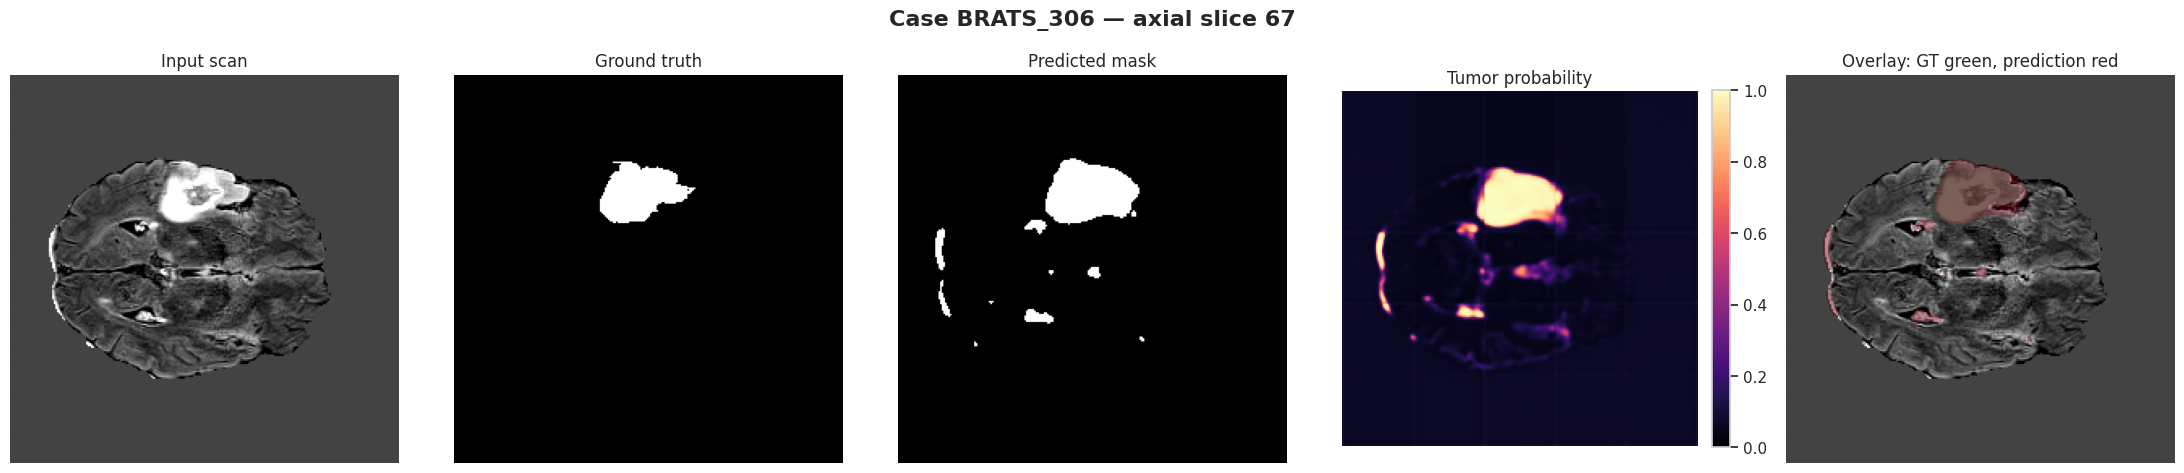

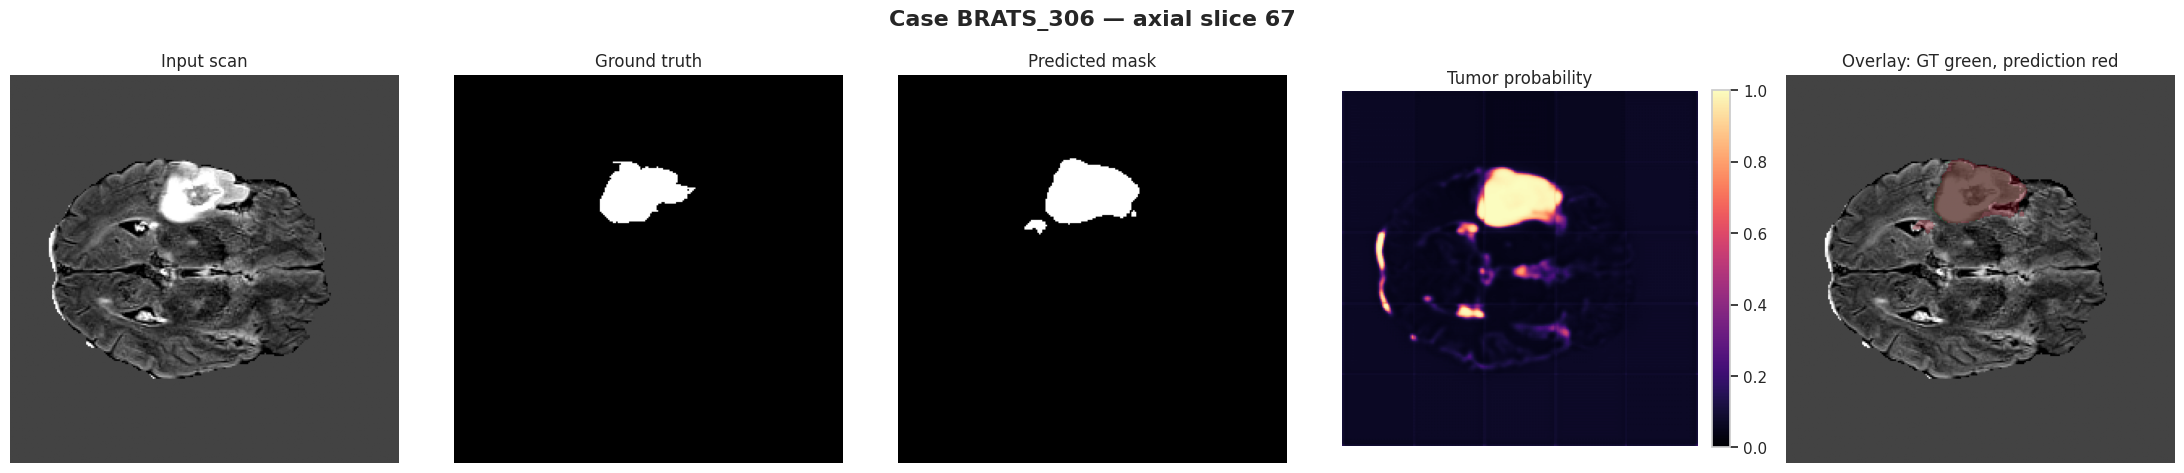

In [43]:
case_idx = 47
case_id = val_dataset.df.iloc[case_idx]["case_id"]

result = predict_full_case(
    model=tumor_model,
    dataset=val_dataset,
    case_idx=case_idx,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
)

# (1, D, H, W) -> (D, H, W)
raw_prediction = result["prediction"].cpu().numpy().squeeze(0)

processed_prediction = connected_component_postprocessing(
    raw_prediction,
    keep_n_components=1,
    min_component_voxels=0,
    connectivity=3,
)

print("Before:", raw_prediction.sum(), "voxels")
print("After: ", processed_prediction.sum(), "voxels")

# Put channel dimension back because plot_case_prediction
# probably expects the original prediction shape.
result_processed = result.copy()
result_processed["prediction"] = torch.from_numpy(
    processed_prediction
).unsqueeze(0)

plot_case_prediction(
    result,
    case_id=case_id,
)

plot_case_prediction(
    result_processed,
    case_id=case_id,
)

In [ ]:
uniform_metrics_lcc = evaluate_validation_model(
    uniform_model,
    val_dataset,
    model_name="uniform LCC",
    postprocess_fn=connected_component_postprocessing,
    postprocess_kwargs={
        "keep_n_components": 1,
        "min_component_voxels": 0,
        "connectivity": 3,
    },
)

summarize_validation_metrics(uniform_metrics_lcc)

uniform LCC: evaluated 73/73 cases


,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,tumor_sensitivity_mean,...,absolute_volume_error_ml_mean,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases
condition,,,,,,,,,,,,,,,,,,,,,
uniform LCC,73,0,173.201628,0.762525,0.231641,0.859339,0.659014,0.235841,0.753369,0.757692,...,24.316219,25.564651,15.454,41.207437,89.569389,18.314693,13.581164,19.977814,5.771,0


### Morph and Connected Component

In [44]:
from scipy.ndimage import (
    binary_erosion,
    binary_dilation,
    generate_binary_structure,
)


def morph_cc_postprocessing(
    mask,
    erosion_iterations=1,
    dilation_iterations=1,
    keep_n_components=1,
    min_component_voxels=0,
    connectivity=3,
):
    """
    Morphological erosion -> connected-component filtering -> dilation.

    Parameters
    ----------
    mask : np.ndarray, shape (D, H, W)
        Binary predicted mask.

    erosion_iterations : int
        Number of erosion iterations before connected-component filtering.
        Larger values shrink the mask more aggressively.

    dilation_iterations : int
        Number of dilation iterations after connected-component filtering.
        Use the same value as erosion_iterations to approximately restore
        the original size.

    keep_n_components : int or None
        Number of largest components to retain.
        1 = keep only the largest component.
        None = keep all components passing the minimum-size rule.

    min_component_voxels : int
        Remove components smaller than this size.

    connectivity : {1, 2, 3}
        3D connectivity:
        1 = 6-connected
        2 = 18-connected
        3 = 26-connected.

    Returns
    -------
    np.ndarray
        Postprocessed Boolean mask with shape (D, H, W).
    """
    mask = np.asarray(mask, dtype=bool)

    if mask.ndim != 3:
        raise ValueError(
            f"Expected a 3D mask with shape (D, H, W), got {mask.shape}"
        )

    if erosion_iterations < 0 or dilation_iterations < 0:
        raise ValueError("erosion_iterations and dilation_iterations must be >= 0")

    if connectivity not in (1, 2, 3):
        raise ValueError("connectivity must be 1, 2, or 3")

    structure = generate_binary_structure(
        rank=3,
        connectivity=connectivity,
    )

    # --------------------------------------------------
    # 1. Erode
    # --------------------------------------------------
    eroded = binary_erosion(
        mask,
        structure=structure,
        iterations=erosion_iterations,
    )

    # --------------------------------------------------
    # 2. Connected-component filtering
    # --------------------------------------------------
    filtered = connected_component_postprocessing(
        eroded,
        keep_n_components=keep_n_components,
        min_component_voxels=min_component_voxels,
        connectivity=connectivity,
    )

    # --------------------------------------------------
    # 3. Dilate back
    # --------------------------------------------------
    restored = binary_dilation(
        filtered,
        structure=structure,
        iterations=dilation_iterations,
    )

    return restored

Before: 80666 voxels
After:  41308 voxels


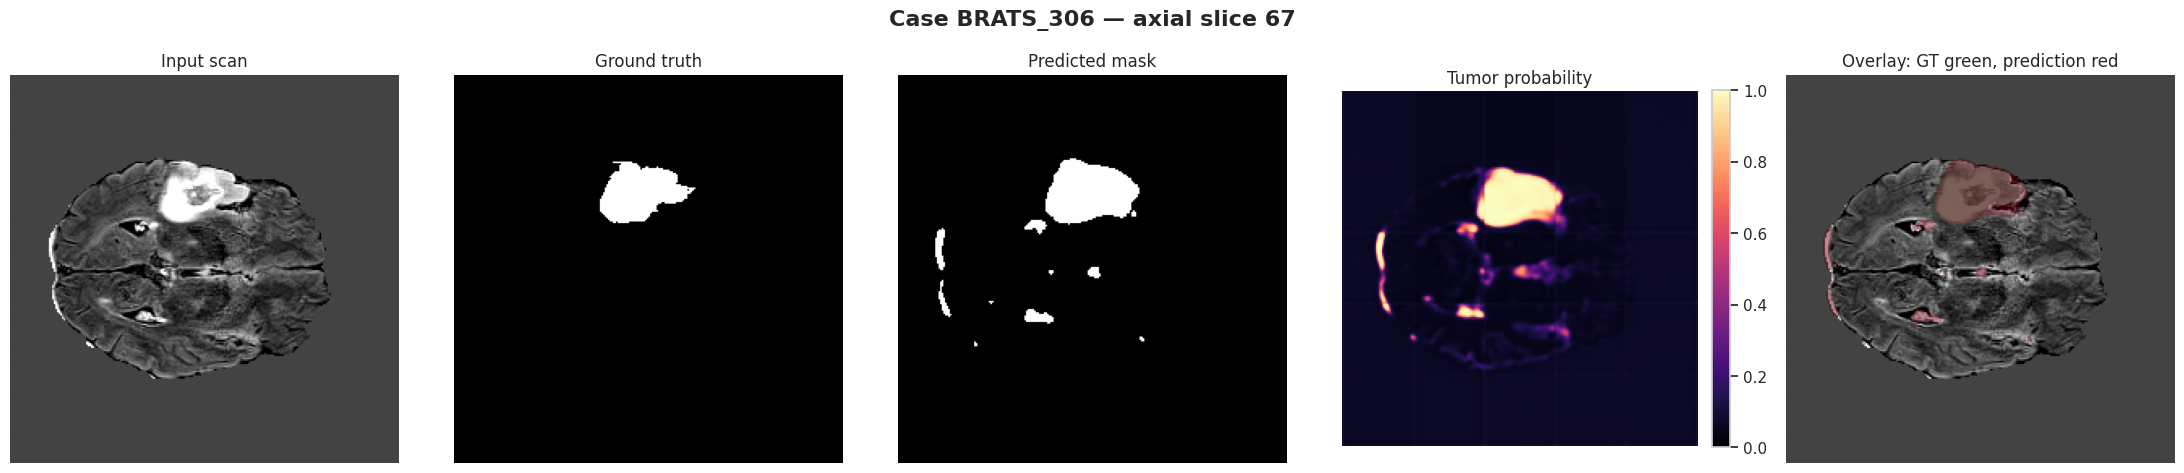

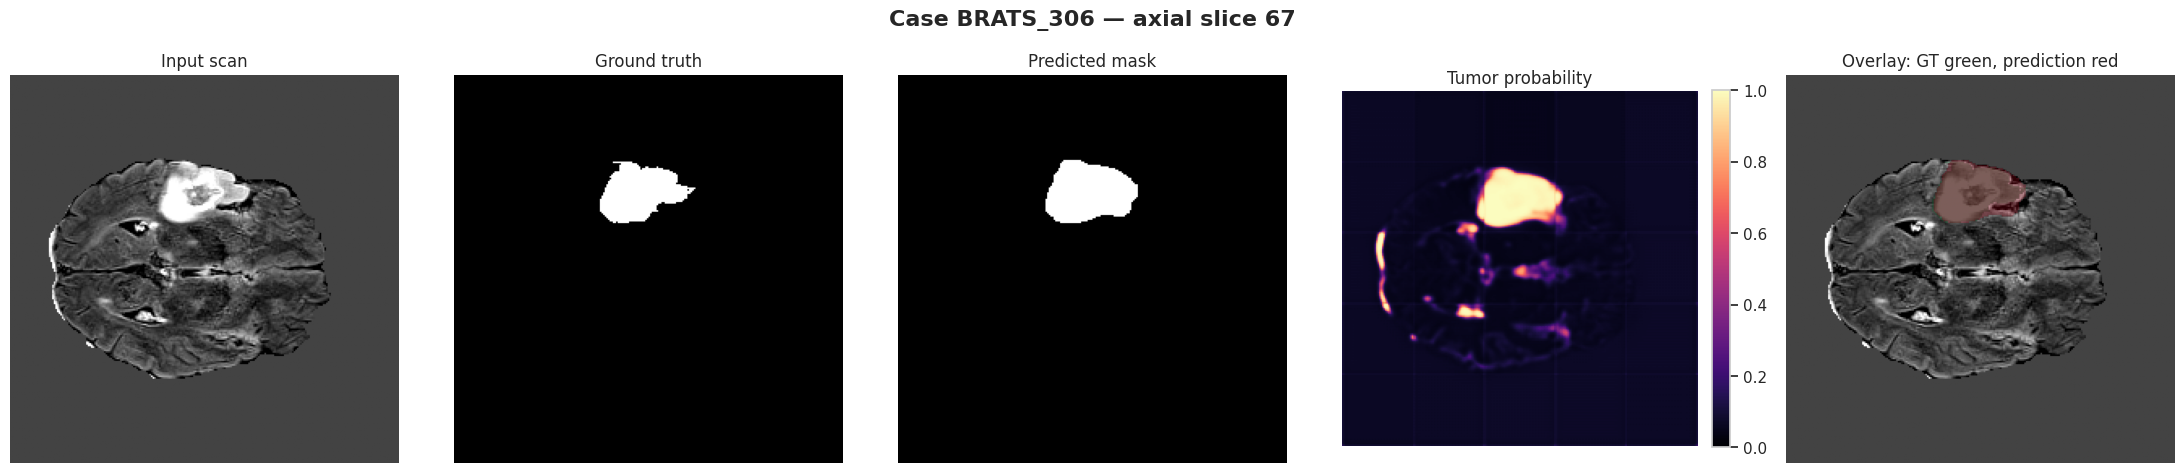

In [45]:
raw_prediction = result["prediction"].cpu().numpy().squeeze(0)

processed_prediction = morph_cc_postprocessing(
    raw_prediction,
    erosion_iterations=2,
    dilation_iterations=2,
    keep_n_components=1,
    min_component_voxels=0,
    connectivity=3,
)

print("Before:", raw_prediction.sum(), "voxels")
print("After: ", processed_prediction.sum(), "voxels")

result_processed = result.copy()
result_processed["prediction"] = torch.from_numpy(
    processed_prediction
).unsqueeze(0)

plot_case_prediction(
    result,
    case_id=case_id,
)

plot_case_prediction(
    result_processed,
    case_id=case_id,
)

Original:    80666 voxels
CC:          45103 voxels
Morph + LCC: 41308 voxels
GT:          32051 voxels


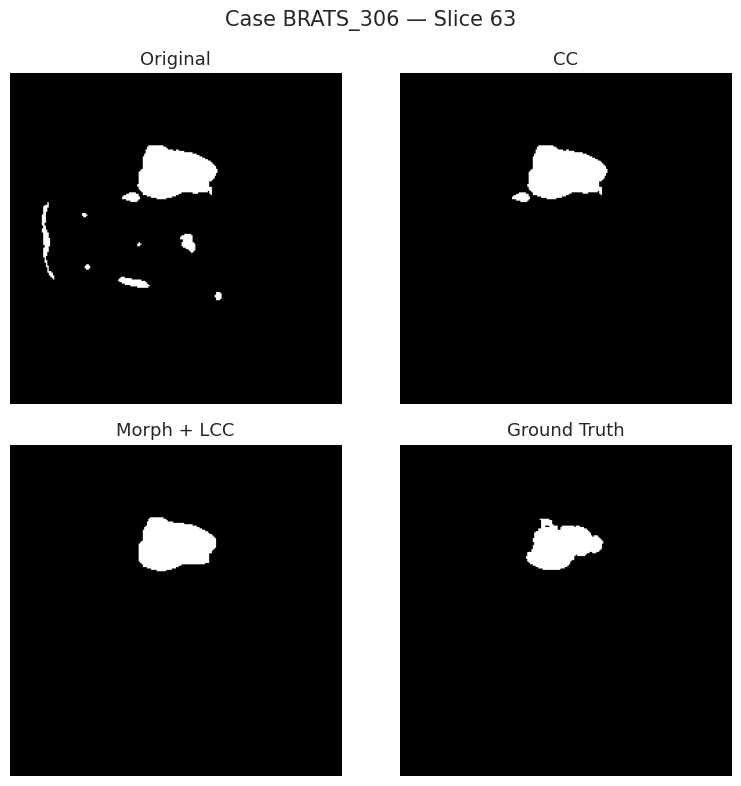

In [46]:
case_idx = 47
case_id = val_dataset.df.iloc[case_idx]["case_id"]

# -----------------------------
# Prediction
# -----------------------------
result = predict_full_case(
    model=tumor_model,
    dataset=val_dataset,
    case_idx=case_idx,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
)

raw_prediction = result["prediction"].cpu().numpy().squeeze(0)

# -----------------------------
# Ground truth
# -----------------------------
ground_truth = result["target"].cpu().numpy().squeeze(0)

# -----------------------------
# CC post-processing
# -----------------------------
cc_prediction = connected_component_postprocessing(
    raw_prediction,
    keep_n_components=1,
    min_component_voxels=0,
    connectivity=3,
)

# -----------------------------
# Morphological + LCC
# -----------------------------
morph_prediction = morph_cc_postprocessing(
    raw_prediction,
    erosion_iterations=2,
    dilation_iterations=2,
    keep_n_components=1,
    min_component_voxels=0,
    connectivity=3,
)

print("Original:   ", raw_prediction.sum(), "voxels")
print("CC:         ", cc_prediction.sum(), "voxels")
print("Morph + LCC:", morph_prediction.sum(), "voxels")
print("GT:         ", ground_truth.sum(), "voxels")

# ============================================================
# Select representative slice
# ============================================================

gt_slices = np.where(
    ground_truth.sum(axis=(1, 2)) > 0
)[0]

if len(gt_slices) > 0:
    slice_idx = gt_slices[len(gt_slices) // 2]
else:
    slice_idx = ground_truth.shape[0] // 2

# ============================================================
# Plot
# ============================================================

masks = [
    ("Original", raw_prediction),
    ("CC", cc_prediction),
    ("Morph + LCC", morph_prediction),
    ("Ground Truth", ground_truth),
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(8, 8),
)

axes = axes.flatten()

for ax, (title, mask) in zip(axes, masks):
    ax.imshow(
        mask[slice_idx],
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(title, fontsize=13)
    ax.axis("off")

fig.suptitle(
    f"Case {case_id} — Slice {slice_idx}",
    fontsize=15,
)

plt.tight_layout()
plt.show()

In [ ]:
# uniform_metrics_morph_one_lcc = evaluate_validation_model(
#     uniform_model,
#     val_dataset,
#     model_name="uniform Morph-1 + LCC",
#     postprocess_fn=morph_cc_postprocessing,
#     postprocess_kwargs={
#         "erosion_iterations": 1,
#         "dilation_iterations": 1,
#         "keep_n_components": 1,
#         "min_component_voxels": 0,
#         "connectivity": 3,
#     },
# )

# summarize_validation_metrics(uniform_metrics_morph_one_lcc)

uniform Morph-1 + LCC: evaluated 73/73 cases


,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,tumor_sensitivity_mean,...,absolute_volume_error_ml_mean,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases
condition,,,,,,,,,,,,,,,,,,,,,
uniform Morph-1 + LCC,73,0,184.62794,0.777082,0.197767,0.868053,0.668915,0.213463,0.766867,0.768265,...,24.250425,25.7983,15.054,40.939013,88.245906,17.880191,12.314575,19.225131,5.578,0


In [ ]:
val_dataset.stride

(48, 48, 48)

In [ ]:
# uniform_metrics_morph_two_lcc = evaluate_validation_model(
#     uniform_model,
#     val_dataset,
#     model_name="uniform Morph-2 + LCC",
#     postprocess_fn=morph_cc_postprocessing,
#     postprocess_kwargs={
#         "erosion_iterations": 2,
#         "dilation_iterations": 2,
#         "keep_n_components": 1,
#         "min_component_voxels": 0,
#         "connectivity": 3,
#     },
# )

uniform Morph-2 + LCC: evaluated 73/73 cases


In [ ]:
postprocessing_result = summarize_validation_metrics(pd.concat([uniform_metrics_lcc, uniform_metrics_morph_one_lcc, uniform_metrics_morph_two_lcc], ignore_index=True))
postprocessing_result.to_csv("output/uniform_postprocessing_result.csv")

pd.set_option("display.max_columns", None)
postprocessing_result.head()

,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,tumor_sensitivity_mean,tumor_sensitivity_std,tumor_sensitivity_median,hd95_mm_mean,hd95_mm_std,hd95_mm_median,predicted_tumor_volume_ml_mean,predicted_tumor_volume_ml_std,predicted_tumor_volume_ml_median,reference_tumor_volume_ml_mean,reference_tumor_volume_ml_std,reference_tumor_volume_ml_median,absolute_volume_error_ml_mean,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases
condition,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
uniform LCC,73,0,173.201628,0.762525,0.231641,0.859339,0.659014,0.235841,0.753369,0.757692,0.253982,0.871704,15.979837,23.474091,5.385165,92.432397,55.562328,83.480,100.764836,62.950123,91.56,24.316219,25.564651,15.454,41.207437,89.569389,18.314693,13.581164,19.977814,5.771,0
uniform Morph-1 + LCC,73,0,184.627940,0.777082,0.197767,0.868053,0.668915,0.213463,0.766867,0.768265,0.226646,0.869000,14.244533,19.325109,5.656854,91.090493,55.353555,83.164,100.764836,62.950123,91.56,24.250425,25.798300,15.054,40.939013,88.245906,17.880191,12.314575,19.225131,5.578,0
uniform Morph-2 + LCC,73,0,185.273915,0.772022,0.200085,0.864637,0.662913,0.216435,0.761550,0.756406,0.230302,0.857354,14.660877,19.404315,5.830952,89.107603,54.720746,82.104,100.764836,62.950123,91.56,24.901041,26.148992,15.234,40.151967,81.262209,17.413651,11.486014,18.505663,5.213,0


In [ ]:
postprocessing_result.columns

Index(['cases', 'empty_predictions', 'time_seconds', 'whole_tumor_dice_mean',
       'whole_tumor_dice_std', 'whole_tumor_dice_median',
       'whole_tumor_iou_mean', 'whole_tumor_iou_std', 'whole_tumor_iou_median',
       'tumor_sensitivity_mean', 'tumor_sensitivity_std',
       'tumor_sensitivity_median', 'hd95_mm_mean', 'hd95_mm_std',
       'hd95_mm_median', 'predicted_tumor_volume_ml_mean',
       'predicted_tumor_volume_ml_std', 'predicted_tumor_volume_ml_median',
       'reference_tumor_volume_ml_mean', 'reference_tumor_volume_ml_std',
       'reference_tumor_volume_ml_median', 'absolute_volume_error_ml_mean',
       'absolute_volume_error_ml_std', 'absolute_volume_error_ml_median',
       'absolute_volume_error_percentage_mean',
       'absolute_volume_error_percentage_std',
       'absolute_volume_error_percentage_median',
       'false_positive_volume_ml_mean', 'false_positive_volume_ml_std',
       'false_positive_volume_ml_median', 'nonfinite_hd95_cases'],
      dtype='obje

In [47]:
row = stride_summary.iloc[[0]].drop(columns="stride")

stride = stride_summary.iloc[0]["stride"]

row["condition"] = f"stride={stride}"

row = row[postprocessing_result.columns]

row.index = ['no postprocessing']

postprocessing_summary = pd.concat(
    [postprocessing_result, row],
    ignore_index=False,
)

postprocessing_summary.to_csv("output/postprocessing_summary.csv")
postprocessing_summary

NameError: name 'postprocessing_result' is not defined

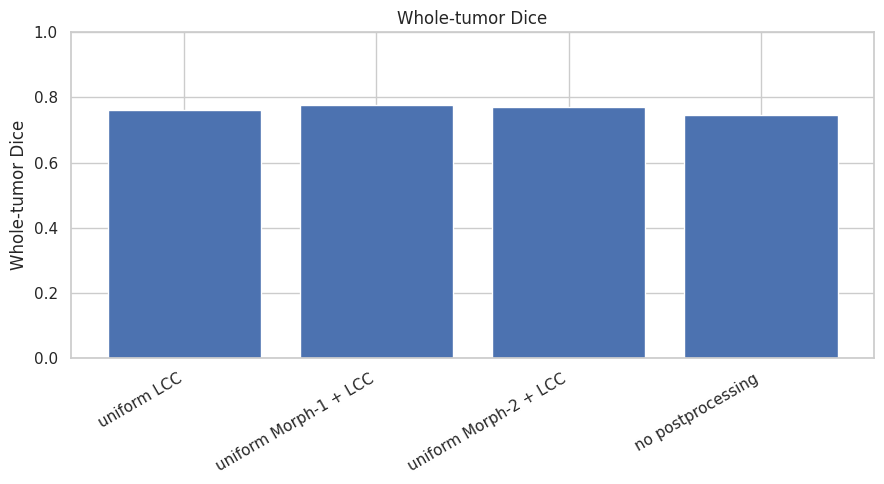

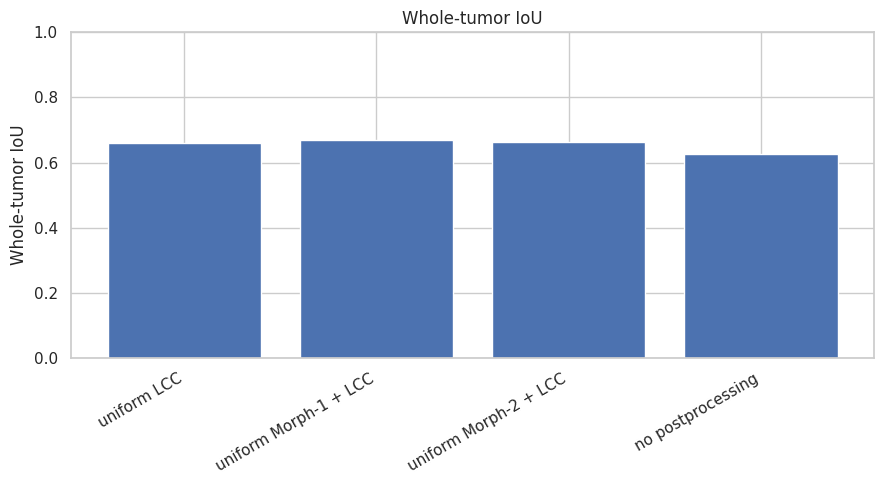

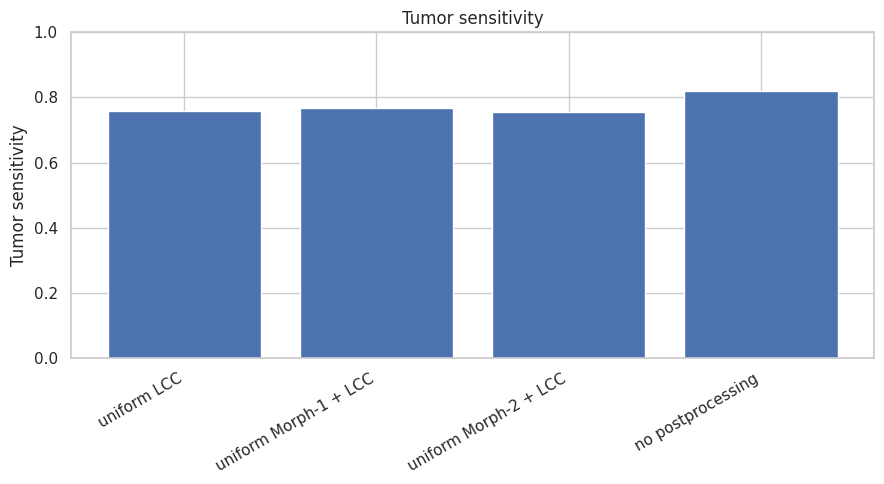

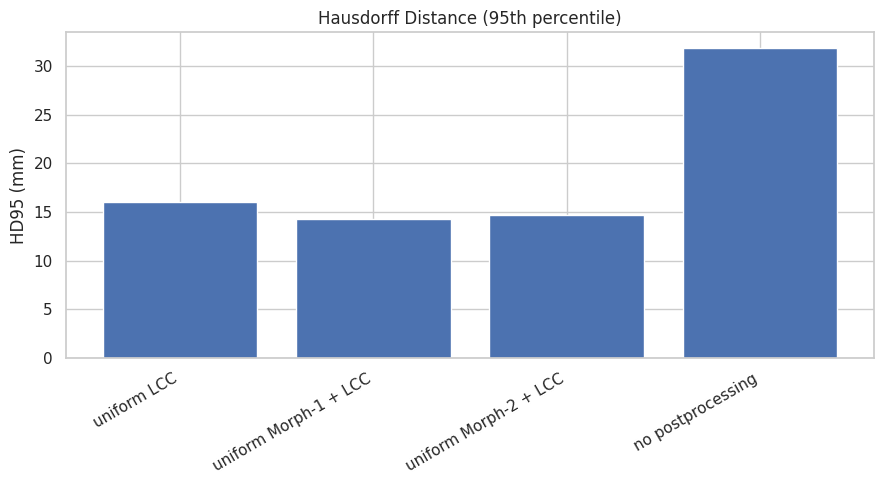

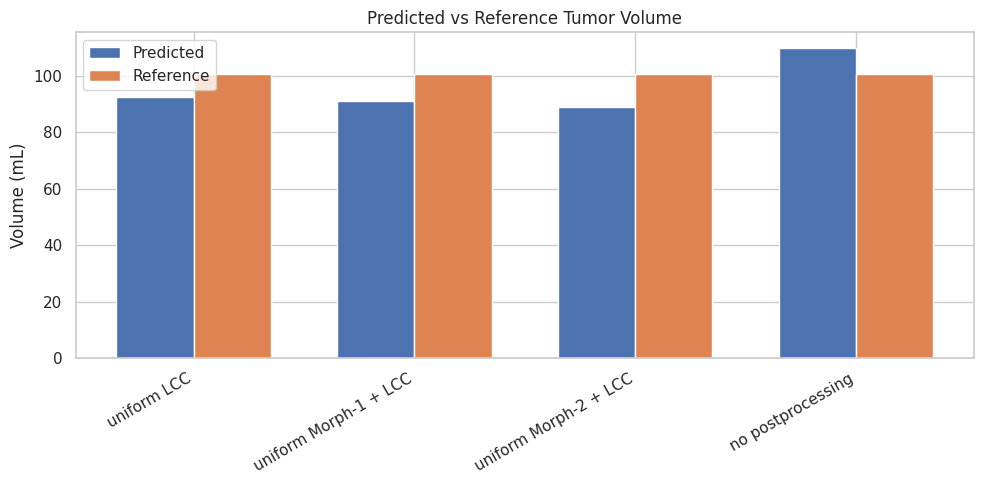

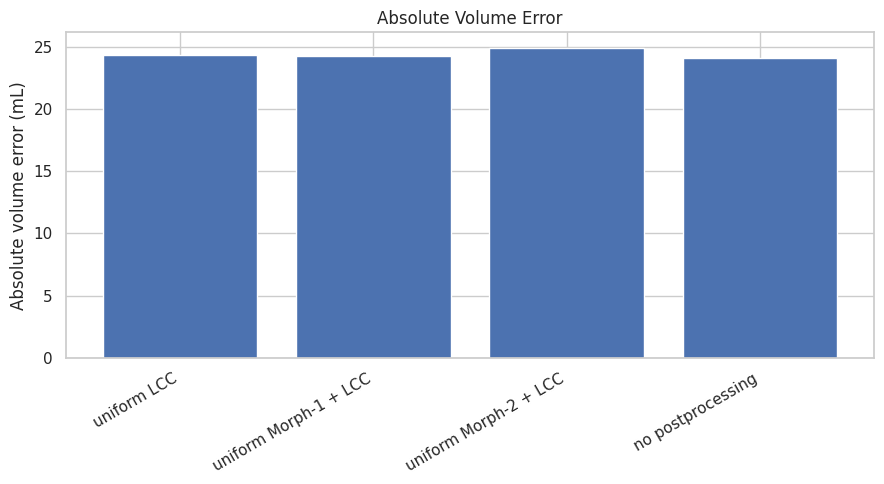

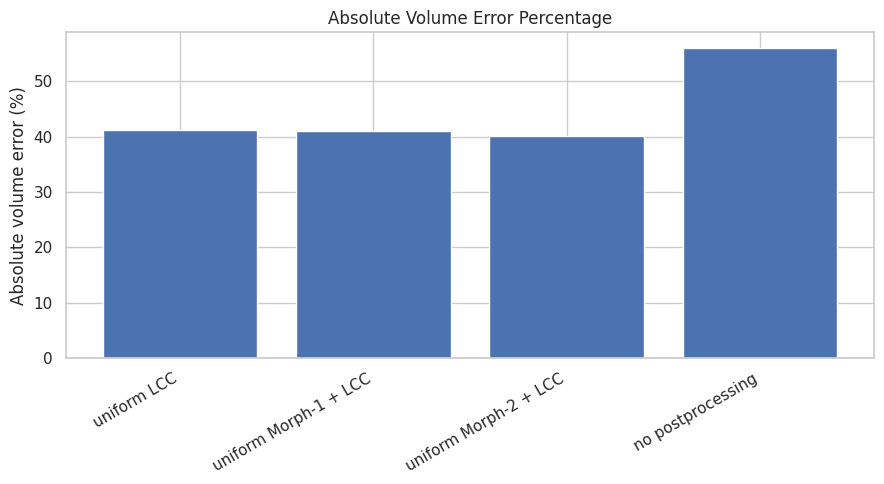

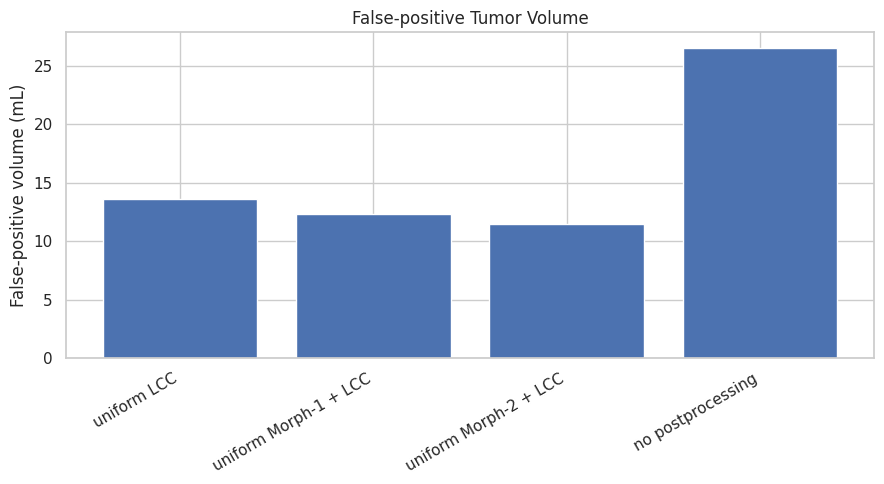

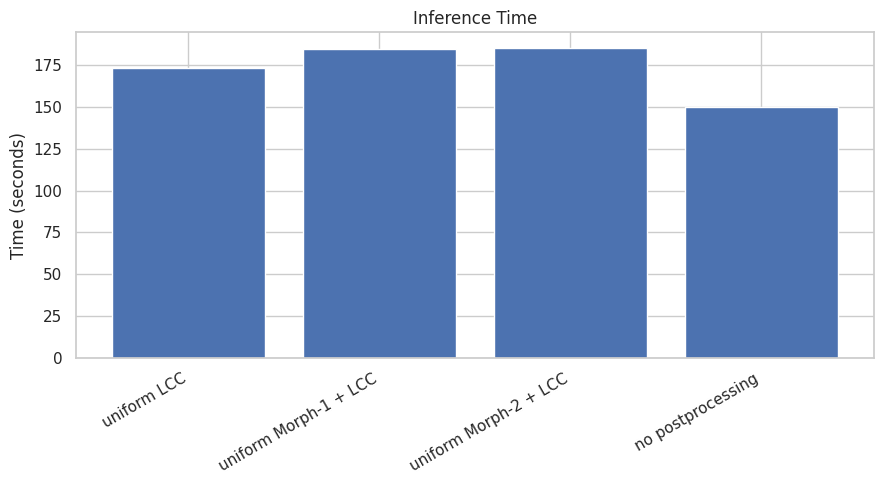

<Figure size 640x480 with 0 Axes>

In [ ]:
df = postprocessing_summary.copy()

# Use condition as the x-axis
conditions = df.index

# ---------------------------------------------------------
# 1. Segmentation quality
# ---------------------------------------------------------
metrics = [
    ("whole_tumor_dice_mean", "Whole-tumor Dice", 0, 1),
    ("whole_tumor_iou_mean", "Whole-tumor IoU", 0, 1),
    ("tumor_sensitivity_mean", "Tumor sensitivity", 0, 1),
]

for col, title, ymin, ymax in metrics:
    plt.figure(figsize=(9, 5))

    x = np.arange(len(df))
    y = df[col].values

    plt.bar(x, y)

    plt.xticks(x, conditions, rotation=30, ha="right")
    plt.ylabel(title)
    plt.title(title)
    plt.ylim(ymin, ymax)

    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# 2. HD95
# ---------------------------------------------------------
plt.figure(figsize=(9, 5))

x = np.arange(len(df))
y = df["hd95_mm_mean"].values

plt.bar(x, y)

plt.xticks(x, conditions, rotation=30, ha="right")
plt.ylabel("HD95 (mm)")
plt.title("Hausdorff Distance (95th percentile)")
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 3. Tumor volume
# ---------------------------------------------------------
x = np.arange(len(df))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    df["predicted_tumor_volume_ml_mean"],
    width,
    label="Predicted",
)

plt.bar(
    x + width / 2,
    df["reference_tumor_volume_ml_mean"],
    width,
    label="Reference",
)

plt.xticks(x, conditions, rotation=30, ha="right")
plt.ylabel("Volume (mL)")
plt.title("Predicted vs Reference Tumor Volume")
plt.legend()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 4. Absolute volume error
# ---------------------------------------------------------
for col, title, ylabel in [
    (
        "absolute_volume_error_ml_mean",
        "Absolute Volume Error",
        "Absolute volume error (mL)",
    ),
    (
        "absolute_volume_error_percentage_mean",
        "Absolute Volume Error Percentage",
        "Absolute volume error (%)",
    ),
]:
    plt.figure(figsize=(9, 5))

    x = np.arange(len(df))
    y = df[col].values

    plt.bar(x, y)

    plt.xticks(x, conditions, rotation=30, ha="right")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# 5. False-positive volume
# ---------------------------------------------------------
plt.figure(figsize=(9, 5))

x = np.arange(len(df))
y = df["false_positive_volume_ml_mean"].values

plt.bar(x, y)

plt.xticks(x, conditions, rotation=30, ha="right")
plt.ylabel("False-positive volume (mL)")
plt.title("False-positive Tumor Volume")

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 6. Runtime
# ---------------------------------------------------------
plt.figure(figsize=(9, 5))

x = np.arange(len(df))
y = df["time_seconds"].values

plt.bar(x, y)

plt.xticks(x, conditions, rotation=30, ha="right")
plt.ylabel("Time (seconds)")
plt.title("Inference Time")

plt.tight_layout()
plt.show()

plt.tight_layout()
plt.show()

### One Morph with test data

In [48]:
test_dataset = BraTSPatchDataset(
    test_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=(48, 48, 48),
    train=False,
)

In [49]:
final_metrics = evaluate_validation_model(
    uniform_model,
    test_dataset,
    model_name="tumor-aware Morph-1 + LCC",
    postprocess_fn=morph_cc_postprocessing,
    postprocess_kwargs={
        "erosion_iterations": 1,
        "dilation_iterations": 1,
        "keep_n_components": 1,
        "min_component_voxels": 0,
        "connectivity": 3,
    },
)

final_summary = summarize_validation_metrics(final_metrics)

tumor-aware Morph-1 + LCC: evaluated 73/73 cases


In [50]:
final_metrics.to_csv("output/final_metrics.csv")
final_summary = summarize_validation_metrics(final_metrics)
final_summary.to_csv("output/final_summary_evaluation_on_test.csv")
final_summary

,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,tumor_sensitivity_mean,...,absolute_volume_error_ml_mean,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases
condition,,,,,,,,,,,,,,,,,,,,,
tumor-aware Morph-1 + LCC,73,0,499.196546,0.827672,0.138947,0.86854,0.72482,0.163121,0.767628,0.813412,...,20.138534,26.175059,11.876,24.300286,59.680674,13.687429,9.352685,10.843415,5.473,0


In [51]:
final_metrics

,model,case_id,postprocessed,whole_tumor_dice,whole_tumor_iou,tumor_sensitivity,hd95_mm,true_positive_voxels,false_positive_voxels,false_negative_voxels,...,reference_tumor_voxels,voxel_volume_mm3,predicted_tumor_volume_ml,reference_tumor_volume_ml,signed_volume_error_ml,absolute_volume_error_ml,absolute_volume_error_percentage,false_positive_volume_ml,empty_prediction,time_seconds
0,tumor-aware Morph-1 + LCC,BRATS_002,True,0.868540,0.767628,0.973470,4.242641,61388,16910,1673,...,63061,1.0,78.298,63.061,15.237,15.237,24.162319,16.910,False,6.706349
1,tumor-aware Morph-1 + LCC,BRATS_012,True,0.877959,0.782467,0.853686,3.605551,18449,1967,3162,...,21611,1.0,20.416,21.611,-1.195,1.195,5.529591,1.967,False,6.839614
2,tumor-aware Morph-1 + LCC,BRATS_016,True,0.874958,0.777711,0.888067,4.472136,73468,11739,9260,...,82728,1.0,85.207,82.728,2.479,2.479,2.996567,11.739,False,6.990183
3,tumor-aware Morph-1 + LCC,BRATS_033,True,0.912715,0.839444,0.854081,4.123106,97378,1988,16637,...,114015,1.0,99.366,114.015,-14.649,14.649,12.848309,1.988,False,6.524259
4,tumor-aware Morph-1 + LCC,BRATS_039,True,0.884161,0.792373,0.877938,3.162278,32496,3997,4518,...,37014,1.0,36.493,37.014,-0.521,0.521,1.407576,3.997,False,6.676478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,tumor-aware Morph-1 + LCC,BRATS_462,True,0.815737,0.688814,0.816333,5.385165,31277,7093,7037,...,38314,1.0,38.370,38.314,0.056,0.056,0.146161,7.093,False,6.801251
69,tumor-aware Morph-1 + LCC,BRATS_466,True,0.850478,0.739853,0.938202,2.828427,15713,4490,1035,...,16748,1.0,20.203,16.748,3.455,3.455,20.629329,4.490,False,6.799945
70,tumor-aware Morph-1 + LCC,BRATS_467,True,0.915687,0.844485,0.848297,3.000000,133818,712,23931,...,157749,1.0,134.530,157.749,-23.219,23.219,14.718952,0.712,False,6.947992
71,tumor-aware Morph-1 + LCC,BRATS_481,True,0.889520,0.801023,0.827631,7.071068,47314,1899,9854,...,57168,1.0,49.213,57.168,-7.955,7.955,13.915127,1.899,False,6.858102


## Three plane error analysis

,selection,case_id,whole_tumor_dice,hd95_mm,signed_volume_error_ml,absolute_volume_error_ml,absolute_volume_error_percentage
0,Best,BRATS_112,0.960,1.732,-3.451,3.451,2.040
1,Median,BRATS_002,0.869,4.243,15.237,15.237,24.162
2,Worst,BRATS_078,0.248,53.768,-6.411,6.411,7.535


,selection,case_id,boundary_error_fraction_within_2mm,mostly_missed_small_components,false_positive_voxels,false_negative_voxels
0,Best,BRATS_112,0.958,1,7484,6634
1,Median,BRATS_002,0.686,0,20924,1137
2,Worst,BRATS_078,0.407,7,82306,20236


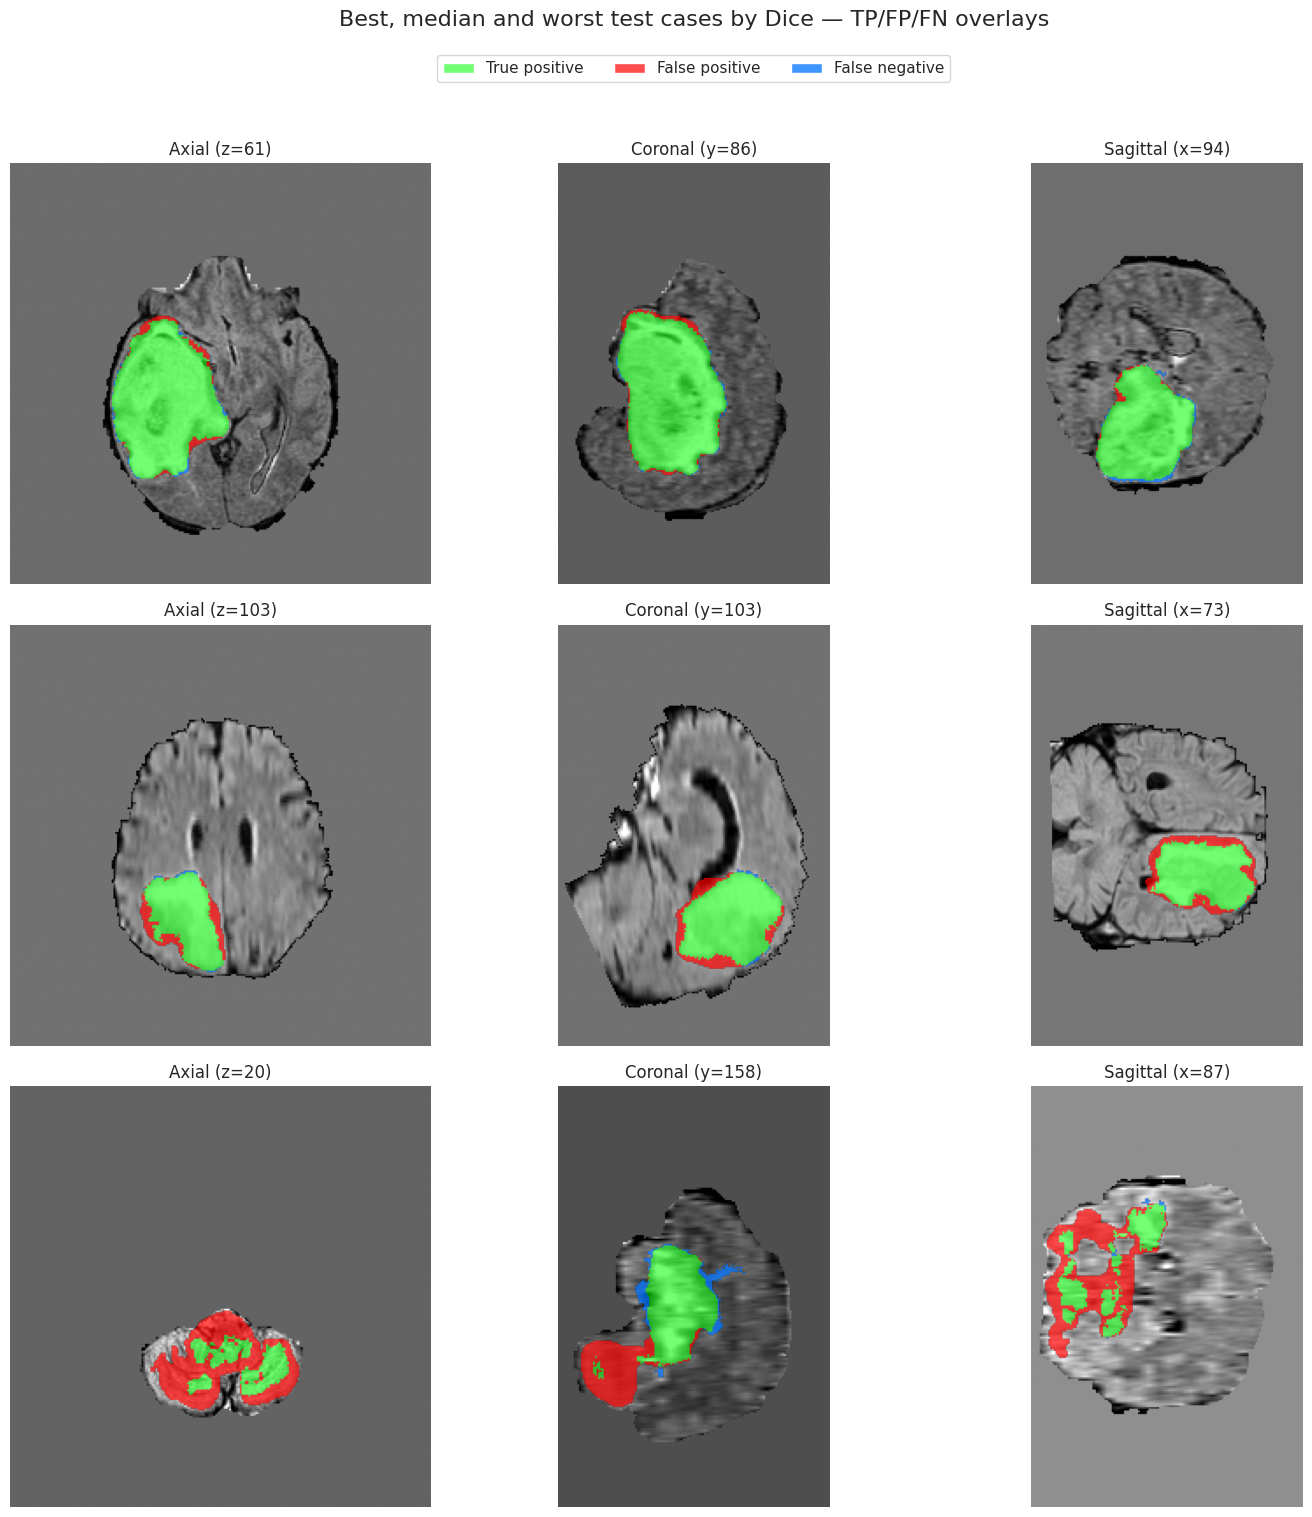

In [52]:
from matplotlib.patches import Patch


def select_best_median_worst_cases(case_metrics):
    """Select the highest, closest-to-median, and lowest Dice cases."""
    metrics = case_metrics.reset_index(drop=True).copy()
    dice = metrics["whole_tumor_dice"]
    median_dice = dice.median()

    selected_indices = {
        "Best": dice.idxmax(),
        "Median": (dice - median_dice).abs().idxmin(),
        "Worst": dice.idxmin(),
    }

    selected = []
    for selection, index in selected_indices.items():
        row = metrics.loc[index].copy()
        row["selection"] = selection
        selected.append(row)

    return pd.DataFrame(selected).reset_index(drop=True)


def regenerate_test_prediction(
    model, dataset, case_id, threshold=0.5, batch_size=2
):
    """Regenerate one test mask using the final inference pipeline."""
    matches = np.flatnonzero(
        dataset.df["case_id"].astype(str).to_numpy() == str(case_id)
    )
    if len(matches) != 1:
        raise ValueError(f"Expected one test case named {case_id}, found {len(matches)}")

    case_idx = int(matches[0])
    result = predict_full_case(
        model, dataset, case_idx, threshold=threshold,
        batch_size=batch_size, device=DEVICE,
    )

    # Match the postprocessing used to produce final_metrics.
    prediction = morph_cc_postprocessing(
        result["prediction"].squeeze(0).numpy(),
        erosion_iterations=1,
        dilation_iterations=1,
        keep_n_components=1,
        min_component_voxels=0,
        connectivity=3,
    )
    result["prediction"] = torch.from_numpy(prediction).bool().unsqueeze(0)
    result["case_idx"] = case_idx
    result["case_id"] = str(case_id)
    return result


def error_diagnostics(result, spacing_dhw, boundary_distance_mm=2.0):
    """Quantify whether errors lie near boundaries or in small structures."""
    target = result["target"].squeeze(0).numpy().astype(bool)
    prediction = result["prediction"].squeeze(0).numpy().astype(bool)
    error = np.logical_xor(target, prediction)

    if target.any() and error.any():
        structure = generate_binary_structure(3, 3)
        target_surface = target & ~binary_erosion(
            target, structure=structure, border_value=0
        )
        distance_to_boundary = distance_transform_edt(
            ~target_surface, sampling=spacing_dhw
        )
        boundary_error_fraction = float(
            (distance_to_boundary[error] <= boundary_distance_mm).mean()
        )
    else:
        boundary_error_fraction = 0.0

    component_labels, component_count = label(
        target, structure=generate_binary_structure(3, 3)
    )
    small_limit = max(100, int(0.05 * target.sum()))
    mostly_missed_small_components = 0
    for component_id in range(1, component_count + 1):
        component = component_labels == component_id
        component_size = int(component.sum())
        component_recall = prediction[component].mean() if component_size else 1.0
        if component_size <= small_limit and component_recall < 0.5:
            mostly_missed_small_components += 1

    return {
        "boundary_error_fraction_within_2mm": boundary_error_fraction,
        "mostly_missed_small_components": mostly_missed_small_components,
        "false_positive_voxels": int(np.logical_and(prediction, ~target).sum()),
        "false_negative_voxels": int(np.logical_and(~prediction, target).sum()),
    }


def _plane_views(volume, mask_union):
    """Return informative axial, coronal and sagittal slices."""
    if mask_union.any():
        z = int(mask_union.sum(axis=(1, 2)).argmax())
        y = int(mask_union.sum(axis=(0, 2)).argmax())
        x = int(mask_union.sum(axis=(0, 1)).argmax())
    else:
        z, y, x = (size // 2 for size in mask_union.shape)

    return [
        (f"Axial (z={z})", volume[z], z, "axial"),
        (f"Coronal (y={y})", volume[:, y, :], y, "coronal"),
        (f"Sagittal (x={x})", volume[:, :, x], x, "sagittal"),
    ]


def _mask_plane(mask, index, plane):
    if plane == "axial":
        return mask[index]
    if plane == "coronal":
        return mask[:, index, :]
    return mask[:, :, index]


def plot_three_plane_error_analysis(selected_cases, predictions, image_channel=0):
    """Plot TP/FP/FN overlays for the selected test cases in three planes."""
    fig, axes = plt.subplots(3, 3, figsize=(15, 15), squeeze=False)

    for row_index, metric_row in selected_cases.iterrows():
        result = predictions[metric_row["case_id"]]
        image = result["image"][image_channel].numpy()
        target = result["target"].squeeze(0).numpy().astype(bool)
        prediction = result["prediction"].squeeze(0).numpy().astype(bool)
        true_positive = target & prediction
        false_positive = ~target & prediction
        false_negative = target & ~prediction
        union = target | prediction

        for column_index, (title, image_slice, index, plane) in enumerate(
            _plane_views(image, union)
        ):
            axis = axes[row_index, column_index]
            image_display = image_slice.T
            finite_nonzero = image_display[
                np.isfinite(image_display) & (image_display != 0)
            ]
            if finite_nonzero.size:
                vmin, vmax = np.percentile(finite_nonzero, [1, 99])
            else:
                vmin, vmax = 0, 1

            tp_slice = _mask_plane(true_positive, index, plane).T
            fp_slice = _mask_plane(false_positive, index, plane).T
            fn_slice = _mask_plane(false_negative, index, plane).T
            overlay = np.zeros((*image_display.shape, 4), dtype=np.float32)
            overlay[tp_slice] = (0.0, 1.0, 0.0, 0.55)
            overlay[fp_slice] = (1.0, 0.0, 0.0, 0.70)
            overlay[fn_slice] = (0.0, 0.45, 1.0, 0.75)

            axis.imshow(image_display, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
            axis.imshow(overlay, origin="lower")
            axis.set_title(title)
            axis.axis("off")

        axes[row_index, 0].set_ylabel(
            f"{metric_row['selection']}: {metric_row['case_id']}\n"
            f"Dice={metric_row['whole_tumor_dice']:.3f}, "
            f"HD95={metric_row['hd95_mm']:.2f} mm, "
            f"|volume error|={metric_row['absolute_volume_error_ml']:.2f} mL",
            fontsize=10,
        )

    legend = [
        Patch(facecolor=(0.0, 1.0, 0.0, 0.55), label="True positive"),
        Patch(facecolor=(1.0, 0.0, 0.0, 0.70), label="False positive"),
        Patch(facecolor=(0.0, 0.45, 1.0, 0.75), label="False negative"),
    ]
    fig.legend(handles=legend, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.985))
    fig.suptitle(
        "Best, median and worst test cases by Dice — TP/FP/FN overlays",
        fontsize=16, y=1.01,
    )
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


selected_test_cases = select_best_median_worst_cases(final_metrics)
comparison_columns = [
    "selection", "case_id", "whole_tumor_dice", "hd95_mm",
    "signed_volume_error_ml", "absolute_volume_error_ml",
    "absolute_volume_error_percentage",
]
display(selected_test_cases[comparison_columns].round(3))

selected_predictions = {}
diagnostic_rows = []
for _, selected_row in selected_test_cases.iterrows():
    case_id = selected_row["case_id"]
    result = regenerate_test_prediction(
        tumor_model, test_dataset, case_id, threshold=0.5, batch_size=2
    )
    selected_predictions[case_id] = result

    dataset_row = test_dataset.df.iloc[result["case_idx"]]
    label_nii = nib.load(test_dataset.root_dir / dataset_row["label_relpath"])
    spacing_xyz = tuple(float(v) for v in label_nii.header.get_zooms()[:3])
    diagnostic = error_diagnostics(result, spacing_dhw=spacing_xyz[::-1])
    diagnostic_rows.append({
        "selection": selected_row["selection"],
        "case_id": case_id,
        **diagnostic,
    })

error_diagnostic_table = pd.DataFrame(diagnostic_rows)
display(error_diagnostic_table.round(3))
plot_three_plane_error_analysis(selected_test_cases, selected_predictions)

worst_diagnostic = error_diagnostic_table.loc[
    error_diagnostic_table["selection"] == "Worst"
].iloc[0]
boundary_fraction = worst_diagnostic["boundary_error_fraction_within_2mm"]
missed_small = int(worst_diagnostic["mostly_missed_small_components"])

In [53]:
display(selected_test_cases[comparison_columns].round(3))


,selection,case_id,whole_tumor_dice,hd95_mm,signed_volume_error_ml,absolute_volume_error_ml,absolute_volume_error_percentage
0,Best,BRATS_112,0.960,1.732,-3.451,3.451,2.040
1,Median,BRATS_002,0.869,4.243,15.237,15.237,24.162
2,Worst,BRATS_078,0.248,53.768,-6.411,6.411,7.535


In [54]:
error_diagnostic_table

,selection,case_id,boundary_error_fraction_within_2mm,mostly_missed_small_components,false_positive_voxels,false_negative_voxels
0,Best,BRATS_112,0.958139,1,7484,6634
1,Median,BRATS_002,0.685826,0,20924,1137
2,Worst,BRATS_078,0.407033,7,82306,20236


## Missing Modality test (bonus)

In [55]:
test_dataset = BraTSPatchDataset(
    test_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=(48, 48, 48),
    train=False,
)

In [56]:
class MissingModalityDataset:
    """Delegate to an existing dataset and zero selected normalized channels."""
    def __init__(self, base_dataset, missing_channels):
        self.base_dataset = base_dataset
        self.missing_channels = tuple(missing_channels)
        self.df = base_dataset.df
        self.root_dir = base_dataset.root_dir
        self.patch_size = base_dataset.patch_size
        self.stride = base_dataset.stride

    def _load_case(self, case_idx):
        image, target = self.base_dataset._load_case(case_idx)
        image = image.clone()
        image[list(self.missing_channels)] = 0
        return image, target

    def _get_starts(self, *args, **kwargs):
        return self.base_dataset._get_starts(*args, **kwargs)

    def _extract_patch(self, *args, **kwargs):
        return self.base_dataset._extract_patch(*args, **kwargs)


def run_missing_modality_stress_test(
    model, dataset, four_channel_metrics, modality_names, batch_size=2
):
    """Evaluate the unchanged model after zeroing each MRI channel."""
    all_results = [
        four_channel_metrics.assign(model="All four channels").copy()
    ]

    for channel, modality_name in enumerate(modality_names):
        ablated_dataset = MissingModalityDataset(dataset, [channel])
        metrics = evaluate_validation_model(
            model,
            ablated_dataset,
            model_name=f"Missing {modality_name}",
            batch_size=batch_size,
            device=DEVICE,
            postprocess_fn=morph_cc_postprocessing,
            postprocess_kwargs={
                "erosion_iterations": 1,
                "dilation_iterations": 1,
                "keep_n_components": 1,
                "min_component_voxels": 0,
                "connectivity": 3,
            },
        )
        all_results.append(metrics)

    case_metrics = pd.concat(all_results, ignore_index=True)
    summary = summarize_validation_metrics(case_metrics)

    report = summary[[
        "whole_tumor_dice_mean",
        "hd95_mm_mean",
        "absolute_volume_error_ml_mean",
    ]].rename(columns={
        "whole_tumor_dice_mean": "Dice",
        "hd95_mm_mean": "HD95_mm",
        "absolute_volume_error_ml_mean": "absolute_volume_error_mL",
    })

    baseline = report.loc["All four channels"]
    report["Dice_change_vs_four_channels"] = report["Dice"] - baseline["Dice"]
    report["HD95_change_mm"] = report["HD95_mm"] - baseline["HD95_mm"]
    report["volume_error_change_mL"] = (
        report["absolute_volume_error_mL"] - baseline["absolute_volume_error_mL"]
    )

    missing_rows = report.drop(index="All four channels")
    most_influential = missing_rows["Dice_change_vs_four_channels"].idxmin()
    print(
        f"Most influential channel by mean Dice decrease: {most_influential}. "
        f"Removing it changed Dice by "
        f"{missing_rows.loc[most_influential, 'Dice_change_vs_four_channels']:+.4f}."
    )
    channel_name = most_influential.replace("Missing ", "")
    channel_roles = {
        "FLAIR": "FLAIR strongly highlights edema, which occupies much of the whole-tumor target.",
        "T1w": "T1w supplies anatomical and tissue-boundary context used to reject normal structures.",
        "T1gd": "T1gd highlights enhancing tumor and helps distinguish active tumor from surrounding tissue.",
        "T2w": "T2w provides fluid-sensitive contrast that helps delineate edema and lesion extent.",
    }
    print(
        "Mechanistic interpretation: "
        + channel_roles.get(channel_name, "The removed channel supplied complementary tumor contrast.")
        + " This interpretation is consistent with the ablation, although the stress test alone does not prove causality."
    )
    return case_metrics, report, most_influential


modality_names = list(modalities.keys())
missing_modality_metrics, missing_modality_report, most_influential_channel = (
    run_missing_modality_stress_test(
        uniform_model, test_dataset, final_metrics, modality_names, batch_size=2
    )
)
display(missing_modality_report.round(4))

Missing FLAIR: evaluated 73/73 cases
Missing T1w: evaluated 73/73 cases
Missing T1gd: evaluated 73/73 cases
Missing T2w: evaluated 73/73 cases
Most influential channel by mean Dice decrease: Missing FLAIR. Removing it changed Dice by -0.7797.
Mechanistic interpretation: FLAIR strongly highlights edema, which occupies much of the whole-tumor target. This interpretation is consistent with the ablation, although the stress test alone does not prove causality.


,Dice,HD95_mm,absolute_volume_error_mL,Dice_change_vs_four_channels,HD95_change_mm,volume_error_change_mL
condition,,,,,,
All four channels,0.8277,10.0984,20.1385,0.0000,0.0000,0.0000
Missing FLAIR,0.0479,64.0375,92.7600,-0.7797,53.9392,72.6215
Missing T1w,0.8307,9.8145,21.4532,0.0030,-0.2838,1.3147
Missing T1gd,0.8285,10.1171,20.0131,0.0009,0.0187,-0.1254
Missing T2w,0.7355,15.6556,35.5151,-0.0922,5.5572,15.3766


In [57]:
missing_modality_report.to_csv("output/missing_modality_report.csv")

## Sliding Window Seam Test (bonus)

0% overlap: evaluated 73/73 cases
25% overlap: evaluated 73/73 cases


,Dice,HD95_mm,absolute_volume_error_mL,total_runtime_seconds,runtime_seconds_per_case,stride_DHW
condition,,,,,,
0% overlap,0.8223,10.9641,19.3738,392.8348,5.3813,"(96, 96, 96)"
25% overlap,0.8315,9.5841,20.1351,392.3660,5.3749,"(72, 72, 72)"
50% overlap,0.8277,10.0984,20.1385,499.1965,6.8383,"(48, 48, 48)"


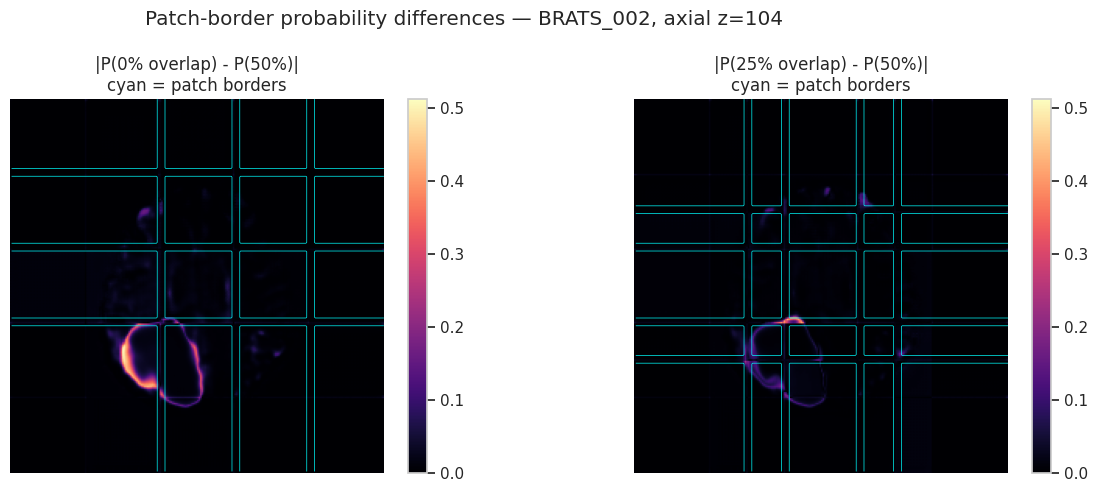

,comparison,mean_absolute_probability_difference_at_borders,mean_absolute_probability_difference_interior,border_to_interior_ratio
0,0% overlap vs 50% overlap,0.007197,0.004461,1.613196
1,25% overlap vs 50% overlap,0.007586,0.003875,1.957606


Highest descriptive test Dice: 25% overlap. This is a comparison only, not a valid basis for retuning the pipeline.


In [58]:
def dataset_with_overlap(base_dataset, overlap_fraction):
    """Create a shallow dataset copy with a requested nominal overlap."""
    if not 0 <= overlap_fraction < 1:
        raise ValueError("overlap_fraction must be in [0, 1)")
    dataset = copy.copy(base_dataset)
    dataset.stride = tuple(
        max(1, int(round(patch * (1 - overlap_fraction))))
        for patch in dataset.patch_size
    )
    return dataset


def run_sliding_window_overlap_test(
    model, base_dataset, fifty_percent_metrics, batch_size=2
):
    """Compare nominal 0%, 25% and 50% sliding-window overlap."""
    overlap_settings = {
        "0% overlap": 0.00,
        "25% overlap": 0.25,
        "50% overlap": 0.50,
    }
    datasets = {
        name: dataset_with_overlap(base_dataset, overlap)
        for name, overlap in overlap_settings.items()
    }

    # final_metrics already contains the identical 50%-overlap evaluation.
    all_results = []
    for name in overlap_settings:
        if name == "50% overlap":
            metrics = fifty_percent_metrics.assign(model=name).copy()
        else:
            metrics = evaluate_validation_model(
                model,
                datasets[name],
                model_name=name,
                batch_size=batch_size,
                device=DEVICE,
                postprocess_fn=morph_cc_postprocessing,
                postprocess_kwargs={
                    "erosion_iterations": 1,
                    "dilation_iterations": 1,
                    "keep_n_components": 1,
                    "min_component_voxels": 0,
                    "connectivity": 3,
                },
            )
        all_results.append(metrics)

    case_metrics = pd.concat(all_results, ignore_index=True)
    summary = summarize_validation_metrics(case_metrics)
    report = summary[[
        "whole_tumor_dice_mean",
        "hd95_mm_mean",
        "absolute_volume_error_ml_mean",
        "time_seconds",
    ]].rename(columns={
        "whole_tumor_dice_mean": "Dice",
        "hd95_mm_mean": "HD95_mm",
        "absolute_volume_error_ml_mean": "absolute_volume_error_mL",
        "time_seconds": "total_runtime_seconds",
    })
    report["runtime_seconds_per_case"] = (
        report["total_runtime_seconds"] / summary["cases"]
    )
    report["stride_DHW"] = [
        str(datasets[name].stride) for name in report.index
    ]
    report = report.reindex(overlap_settings.keys())
    return case_metrics, report, datasets


def _axis_patch_border_mask(size, patch, stride, width=2):
    starts = test_dataset._get_starts(size, patch, stride)
    mask = np.zeros(size, dtype=bool)
    for start in starts:
        for edge in (start, start + patch):
            if 0 < edge < size:
                mask[max(0, edge - width):min(size, edge + width + 1)] = True
    return mask


def patch_border_mask_3d(shape_dhw, patch_size, stride, width=2):
    """Mask voxels within `width` voxels of an internal patch edge."""
    axis_masks = [
        _axis_patch_border_mask(size, patch, step, width)
        for size, patch, step in zip(shape_dhw, patch_size, stride)
    ]
    return (
        axis_masks[0][:, None, None]
        | axis_masks[1][None, :, None]
        | axis_masks[2][None, None, :]
    )


def plot_patch_border_probability_differences(
    probability_results, overlap_datasets, case_id, border_width=2
):
    """Compare lower-overlap probabilities with the 50%-overlap result."""
    reference_probability = (
        probability_results["50% overlap"]["probability"][0].numpy()
    )
    target = probability_results["50% overlap"]["target"][0].numpy().astype(bool)
    z = int(target.sum(axis=(1, 2)).argmax()) if target.any() else target.shape[0] // 2

    comparison_names = ["0% overlap", "25% overlap"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), squeeze=False)
    diagnostic_rows = []
    difference_maps = {
        name: np.abs(
            probability_results[name]["probability"][0].numpy()
            - reference_probability
        )
        for name in comparison_names
    }
    shared_vmax = max(
        max(float(difference.max()), 1e-6)
        for difference in difference_maps.values()
    )

    for axis, name in zip(axes[0], comparison_names):
        difference = difference_maps[name]
        dataset = overlap_datasets[name]
        border_mask = patch_border_mask_3d(
            difference.shape, dataset.patch_size, dataset.stride, border_width
        )

        seam_mean = float(difference[border_mask].mean())
        interior_mean = float(difference[~border_mask].mean())
        diagnostic_rows.append({
            "comparison": f"{name} vs 50% overlap",
            "mean_absolute_probability_difference_at_borders": seam_mean,
            "mean_absolute_probability_difference_interior": interior_mean,
            "border_to_interior_ratio": seam_mean / max(interior_mean, 1e-8),
        })

        in_plane_border = (
            _axis_patch_border_mask(
                difference.shape[1], dataset.patch_size[1], dataset.stride[1], border_width
            )[:, None]
            | _axis_patch_border_mask(
                difference.shape[2], dataset.patch_size[2], dataset.stride[2], border_width
            )[None, :]
        )
        plot = axis.imshow(
            difference[z].T, cmap="magma", vmin=0,
            vmax=shared_vmax, origin="lower",
        )
        axis.contour(
            in_plane_border.T, levels=[0.5], colors="cyan", linewidths=0.5,
            origin="lower",
        )
        axis.set_title(f"|P({name}) - P(50%)|\ncyan = patch borders")
        axis.axis("off")
        fig.colorbar(plot, ax=axis, fraction=0.046, pad=0.04)

    fig.suptitle(f"Patch-border probability differences — {case_id}, axial z={z}")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(diagnostic_rows)


overlap_metrics, overlap_report, overlap_datasets = run_sliding_window_overlap_test(
    uniform_model, test_dataset, final_metrics, batch_size=2
)
display(overlap_report.round(4))

# Use the median-Dice case only for a representative seam visualization.
seam_case = select_best_median_worst_cases(final_metrics).query(
    "selection == 'Median'"
).iloc[0]
seam_case_id = seam_case["case_id"]
seam_case_index = int(np.flatnonzero(
    test_dataset.df["case_id"].astype(str).to_numpy() == str(seam_case_id)
)[0])
probability_results = {
    name: predict_full_case(
        tumor_model, dataset, seam_case_index, threshold=0.5,
        batch_size=2, device=DEVICE,
    )
    for name, dataset in overlap_datasets.items()
}
seam_probability_report = plot_patch_border_probability_differences(
    probability_results, overlap_datasets, seam_case_id
)
display(seam_probability_report.round(6))

best_descriptive_overlap = overlap_report["Dice"].idxmax()
print(
    f"Highest descriptive test Dice: {best_descriptive_overlap}. "
    "This is a comparison only, not a valid basis for retuning the pipeline."
)

In [62]:
overlap_report.to_csv("output/overlap_report.csv")
seam_probability_report.to_csv("output/seam_probability_report.csv")